# Alvarez-Macovski Dual-Energy CT Demo

This notebook demonstrates the **Alvarez-Macovski (AM)** algorithm for dual-energy computed tomography (DECT). The core idea: the linear attenuation coefficient of any material can be written as a linear combination of just two basis functions — one for the photoelectric effect and one for Compton scattering.

$$\mu(x, y, E) = a_1(x,y)\,f_1(E) + a_2(x,y)\,f_2(E)$$

We will:
1. Define the two basis functions $f_1(E)$ and $f_2(E)$
2. Simulate polychromatic X-ray spectra at two energies
3. Forward-project a simple 2-material phantom using Beer-Lambert
4. Solve the nonlinear system to decompose back into $A_1$ and $A_2$ sinograms
5. Visualize the material maps

## 0. Process Overview

The full pipeline at a glance. Every panel below is generated by running the phantom defined in this notebook through each stage — object → forward projection → polychromatic measurement → Alvarez–Macovski decomposition → reconstruction → physical maps. See `make_am_process_diagram.py` for the code that produces it.

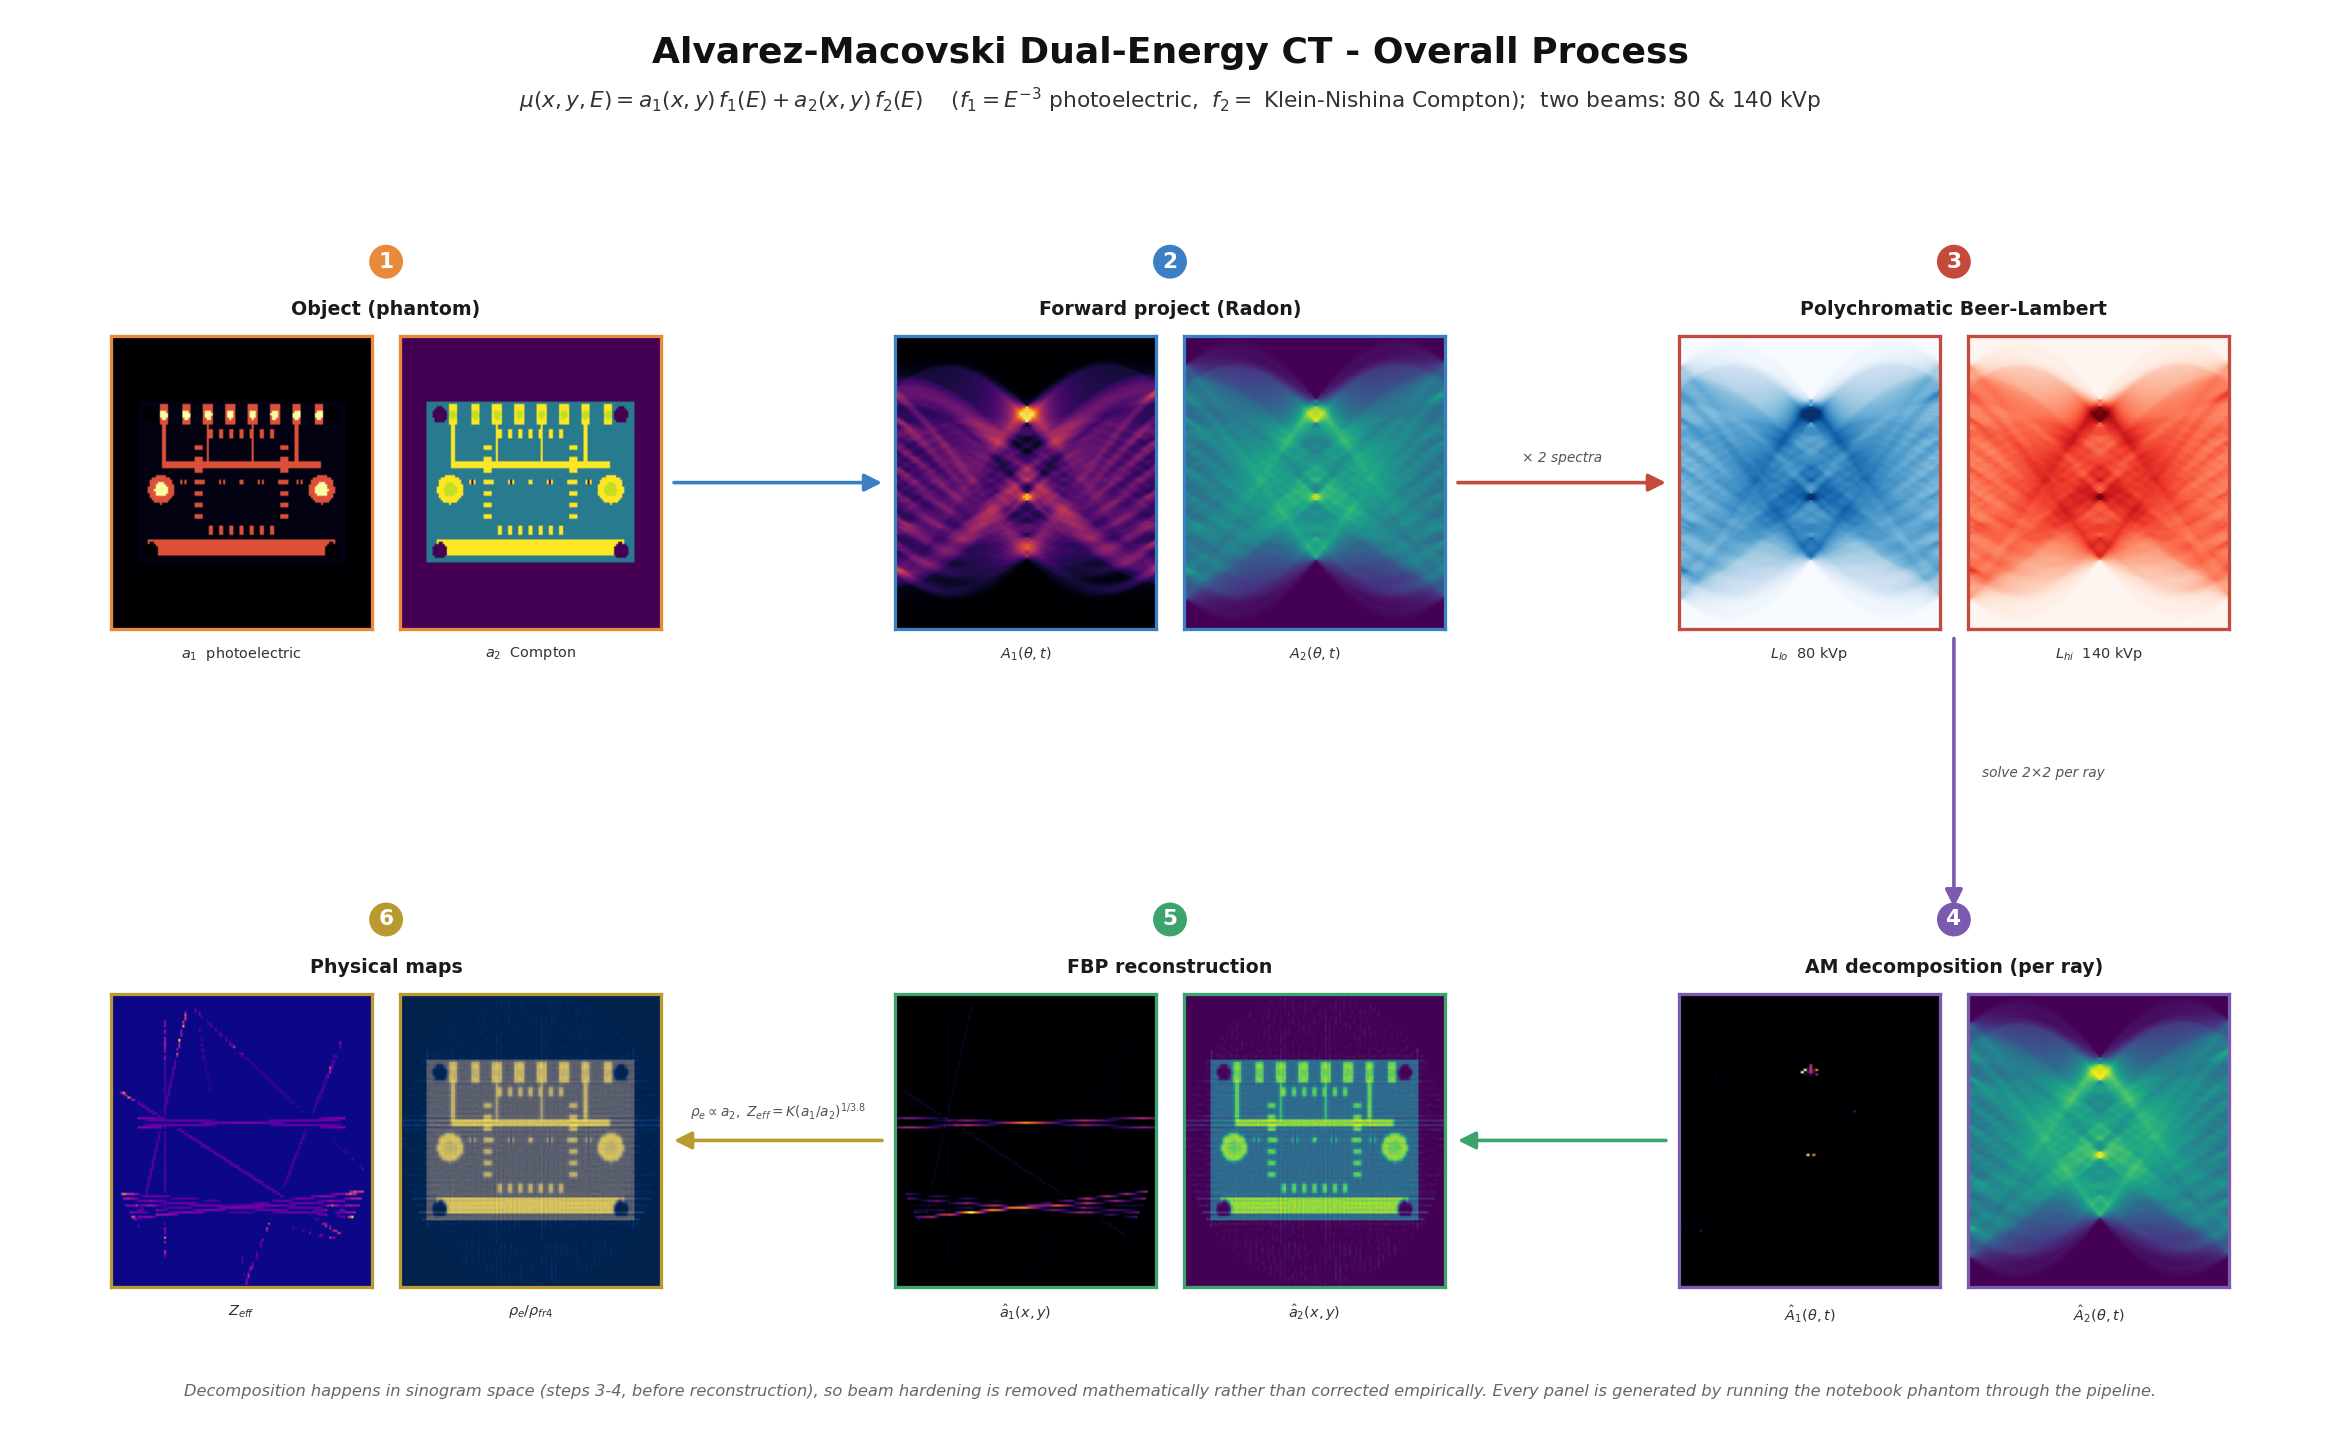

In [49]:
# Overview storyboard: runs the full phantom pipeline and embeds the real
# generated image at every step. See make_am_process_diagram.py.
import os
from IPython.display import Image, display
import make_am_process_diagram as amd

if not os.path.exists(amd.OUT_PATH):
    amd.main()
display(Image(amd.OUT_PATH))

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from scipy.integrate import quad

plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 12})

## 1. Basis Functions

The two physical mechanisms driving X-ray attenuation:

- **Photoelectric effect**: $f_1(E) = E^{-3}$
- **Compton scattering** (Klein-Nishina formula): $f_2(E) = f_{KN}(E)$

The Klein-Nishina function describes how photons scatter off free electrons and is the quantum-mechanical cross-section for Compton scattering.

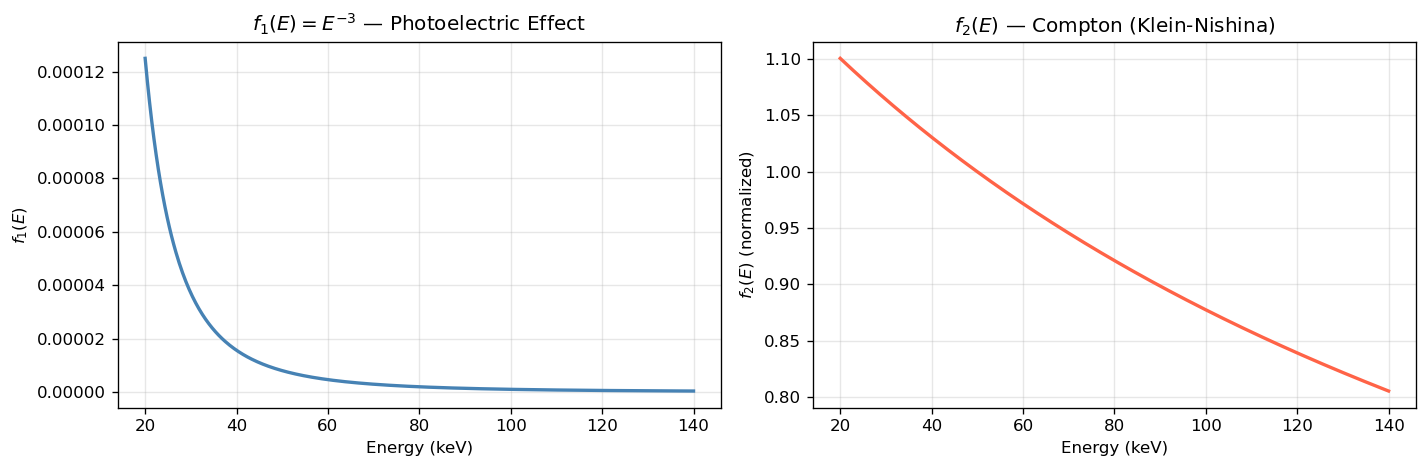

In [51]:
def f1(E):
    """Photoelectric basis function."""
    return E**(-3)

def klein_nishina(E):
    """
    Klein-Nishina Compton scattering cross-section (normalized).
    E in keV. Uses the standard dimensionless photon energy alpha = E / 511 keV.
    Returns the total electronic cross-section (arbitrary units, normalized to 1 at low E).
    """
    alpha = E / 511.0  # dimensionless photon energy (electron rest mass = 511 keV)
    # Klein-Nishina formula for total cross section
    term1 = (1 + alpha) / alpha**3
    term2 = (2*alpha*(1 + alpha)) / (1 + 2*alpha) - np.log(1 + 2*alpha)
    term3 = np.log(1 + 2*alpha) / (2*alpha)
    term4 = (1 + 3*alpha) / (1 + 2*alpha)**2
    sigma = term1 * term2 + term3 - term4
    return sigma

# Normalize f2 to 1 at E=50 keV for numerical convenience
_kn_ref = klein_nishina(50.0)
def f2(E):
    """Compton (Klein-Nishina) basis function, normalized to 1 at 50 keV."""
    return klein_nishina(E) / _kn_ref

# Plot both basis functions
E_range = np.linspace(20, 140, 500)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(E_range, f1(E_range), color="steelblue", lw=2)
axes[0].set(title="$f_1(E) = E^{-3}$ — Photoelectric Effect",
            xlabel="Energy (keV)", ylabel="$f_1(E)$")
axes[0].grid(alpha=0.3)

axes[1].plot(E_range, f2(E_range), color="tomato", lw=2)
axes[1].set(title="$f_2(E)$ — Compton (Klein-Nishina)",
            xlabel="Energy (keV)", ylabel="$f_2(E)$ (normalized)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Polychromatic X-ray Spectra

Real CT scanners emit a broad spectrum of X-ray energies (bremsstrahlung), not a single energy. We model two spectra — a **low-kVp** (80 kV) and a **high-kVp** (140 kV) beam — using a simple triangular approximation. In practice these come from measured tube spectra.

C:\Users\patri\AppData\Local\Temp\ipykernel_8536\334324383.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  phi /= np.trapz(phi, E)  # normalize so integral = 1


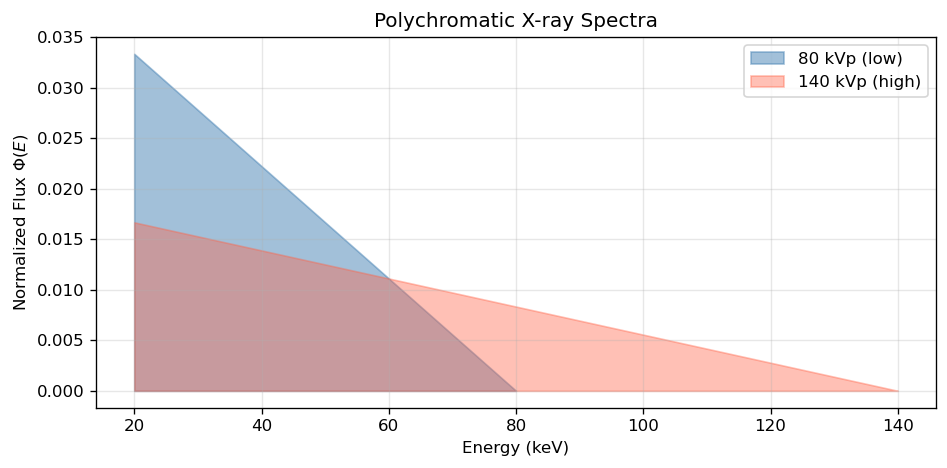

In [52]:
def make_spectrum(E_min, E_max, n_bins=200):
    """
    Simple triangular bremsstrahlung spectrum approximation.
    Peaks near E_min, falls off linearly to zero at E_max.
    """
    E = np.linspace(E_min, E_max, n_bins)
    phi = np.maximum(0, (E_max - E) / (E_max - E_min))
    phi /= np.trapz(phi, E)  # normalize so integral = 1
    return E, phi

E_lo, phi_lo = make_spectrum(20, 80)   # 80 kVp beam
E_hi, phi_hi = make_spectrum(20, 140)  # 140 kVp beam

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(E_lo, phi_lo, alpha=0.5, color="steelblue", label="80 kVp (low)")
ax.fill_between(E_hi, phi_hi, alpha=0.4, color="tomato", label="140 kVp (high)")
ax.set(xlabel="Energy (keV)", ylabel="Normalized Flux $\\Phi(E)$",
       title="Polychromatic X-ray Spectra")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Forward Model — Beer-Lambert with Polychromatic Beam

For a ray through a material with line integrals $A_1$ (photoelectric) and $A_2$ (Compton), the measured log-attenuation at spectrum $k$ is:

$$L_k = -\ln\!\left(\int \Phi_k(E)\,\exp\!\bigl[-A_1 f_1(E) - A_2 f_2(E)\bigr]\,dE\right)$$

This is the **polychromatic Beer-Lambert** law. Note: it is **nonlinear** in $A_1$ and $A_2$, which is what causes beam-hardening artifacts when ignored.

C:\Users\patri\AppData\Local\Temp\ipykernel_8536\2414453694.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  transmitted = np.trapz(phi * np.exp(exponent), E)


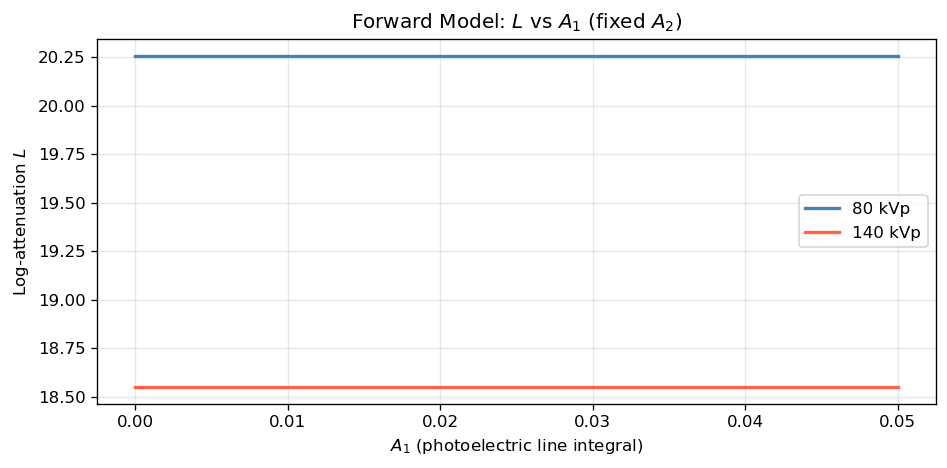

In [53]:
def forward_measurement(A1, A2, E, phi):
    """
    Compute log-attenuation L = -ln( ∫ Φ(E) exp[-A1·f1(E) - A2·f2(E)] dE )
    using discrete spectrum (E, phi) via trapz integration.
    """
    exponent = -A1 * f1(E) - A2 * f2(E)
    transmitted = np.trapz(phi * np.exp(exponent), E)
    return -np.log(transmitted)

# Quick sanity check: compute L for a range of A1 values, A2 fixed
A1_vals = np.linspace(0, 0.05, 100)
A2_fixed = 20.0

L_lo = [forward_measurement(a1, A2_fixed, E_lo, phi_lo) for a1 in A1_vals]
L_hi = [forward_measurement(a1, A2_fixed, E_hi, phi_hi) for a1 in A1_vals]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(A1_vals, L_lo, color="steelblue", lw=2, label="80 kVp")
ax.plot(A1_vals, L_hi, color="tomato", lw=2, label="140 kVp")
ax.set(xlabel="$A_1$ (photoelectric line integral)", ylabel="Log-attenuation $L$",
       title="Forward Model: $L$ vs $A_1$ (fixed $A_2$)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Phantom — Printed Circuit Board

We use a simple 2D **printed circuit board (PCB)**, matching the kind of object in the `20250701_PCB2` scan. Three materials sit on an air background:

- **FR4 substrate** (glass-reinforced epoxy): low $a_1$, low $a_2$ — the board itself
- **Copper**: traces, pads, ground rail and plated vias — high $a_1$, high $a_2$
- **Solder**: joints / bumps on the pads — highest $a_1$ (Sn-based, higher $Z$)

Drilled mounting holes and via barrels are air. The spatial maps $a_1(x,y)$ and $a_2(x,y)$ are the ground truth.

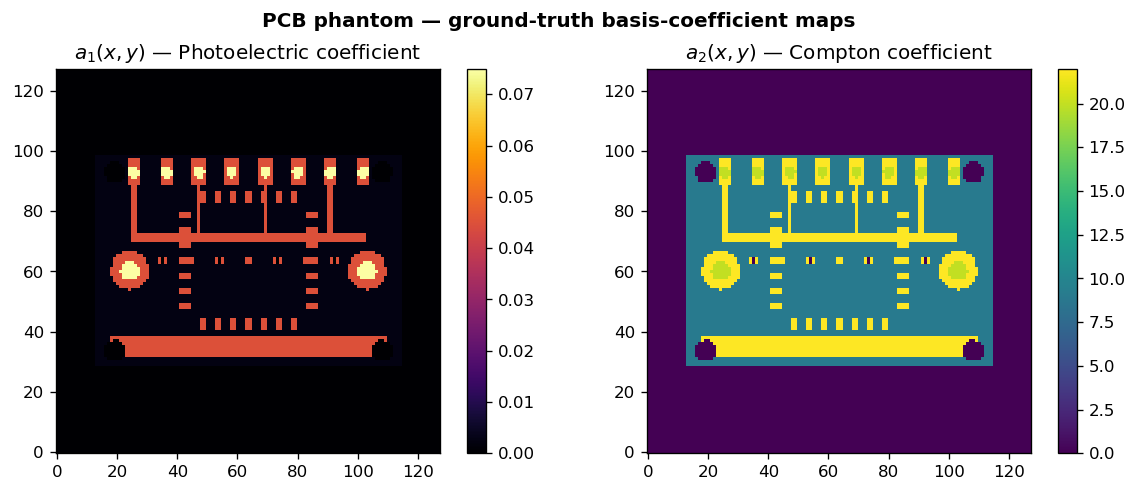

In [54]:
N = 128  # image size
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

# --- PCB material coefficients (a1 photoelectric, a2 Compton) ---
# Units are illustrative; chosen so substrate / copper / solder separate cleanly
# in (a1, a2) space while keeping line integrals within the inversion-LUT range.
# The Z_eff values noted below are illustrative (compressed), NOT physical --
# real copper is Z~29 and Sn-based solder Z~50; here they only need to keep the
# ordering fr4 < copper < solder.
MATERIALS = {
    "air":    (0.0,    0.0),    # board outline, drilled holes
    "fr4":    (0.0025, 9.0),    # glass-epoxy substrate    (illustrative Z_eff ~ 12)
    "copper": (0.045,  22.0),   # traces, pads, ground rail (illustrative Z_eff ~ 20)
    "solder": (0.075,  20.0),   # solder joints / bumps     (illustrative Z_eff ~ 24)
}

def circle(cx, cy, r):
    return (X - cx)**2 + (Y - cy)**2 < r**2

def rect(x0, x1, y0, y1):
    return (X >= x0) & (X <= x1) & (Y >= y0) & (Y <= y1)

# 1. FR4 substrate (the board outline)
board_mask = rect(-0.80, 0.80, -0.55, 0.55)

# 2. Copper: ground rail, edge-connector fingers, IC pad ring, power pads,
#    routing traces, horizontal bus and plated vias
copper_mask = np.zeros((N, N), bool)
copper_mask |= rect(-0.72, 0.72, -0.50, -0.40)            # bottom ground rail
finger_x = np.linspace(-0.60, 0.60, 8)
for fx in finger_x:                                       # edge-connector fingers
    copper_mask |= rect(fx - 0.035, fx + 0.035, 0.40, 0.53)
for p in np.linspace(-0.24, 0.24, 7):                     # central IC pad ring
    copper_mask |= rect(p - 0.018, p + 0.018, 0.30, 0.36)
    copper_mask |= rect(p - 0.018, p + 0.018, -0.36, -0.30)
    copper_mask |= rect(-0.36, -0.30, p - 0.018, p + 0.018)
    copper_mask |= rect(0.30, 0.36, p - 0.018, p + 0.018)
copper_mask |= circle(-0.62, -0.05, 0.10)                 # power pads
copper_mask |= circle(0.62, -0.05, 0.10)
for fx in finger_x[::2]:                                  # routing traces
    copper_mask |= rect(fx - 0.012, fx + 0.012, 0.12, 0.40)
copper_mask |= rect(-0.62, 0.62, 0.10, 0.135)             # horizontal bus
via_centres = [(vx, 0.0) for vx in np.linspace(-0.45, 0.45, 7)]
for vx, vy in via_centres:
    copper_mask |= circle(vx, vy, 0.022)

# 3. Solder joints on the connector fingers and the power pads
solder_mask = np.zeros((N, N), bool)
for fx in finger_x:
    solder_mask |= circle(fx, 0.46, 0.030)
solder_mask |= circle(-0.62, -0.05, 0.05)
solder_mask |= circle(0.62, -0.05, 0.05)

# 4. Drilled holes (air): mounting holes + via barrels
hole_mask = np.zeros((N, N), bool)
for hx, hy in [(-0.70, 0.46), (0.70, 0.46), (-0.70, -0.47), (0.70, -0.47)]:
    hole_mask |= circle(hx, hy, 0.055)                    # mounting holes
for vx, vy in via_centres:
    hole_mask |= circle(vx, vy, 0.009)                    # drilled via barrels

# Compose the (a1, a2) ground-truth maps (later layers override earlier ones)
a1_map = np.zeros((N, N))
a2_map = np.zeros((N, N))
for mask, mat in [(board_mask, "fr4"), (copper_mask, "copper"),
                  (solder_mask, "solder"), (hole_mask, "air")]:
    a1_map[mask], a2_map[mask] = MATERIALS[mat]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(a1_map, cmap="inferno", origin="lower")
axes[0].set_title("$a_1(x,y)$ — Photoelectric coefficient"); plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(a2_map, cmap="viridis", origin="lower")
axes[1].set_title("$a_2(x,y)$ — Compton coefficient"); plt.colorbar(im1, ax=axes[1])
fig.suptitle("PCB phantom — ground-truth basis-coefficient maps", fontweight="bold")
plt.tight_layout(); plt.show()

## 5. Parallel-Beam Forward Projection (Sinogram)

We compute line integrals $A_1$ and $A_2$ along parallel rays (a simplified Radon transform using column sums — equivalent to a 0° parallel-beam projection for demonstration). Then we apply the polychromatic Beer-Lambert forward model to get sinograms $L_{lo}$ and $L_{hi}$.

C:\Users\patri\AppData\Local\Temp\ipykernel_8536\2414453694.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  transmitted = np.trapz(phi * np.exp(exponent), E)


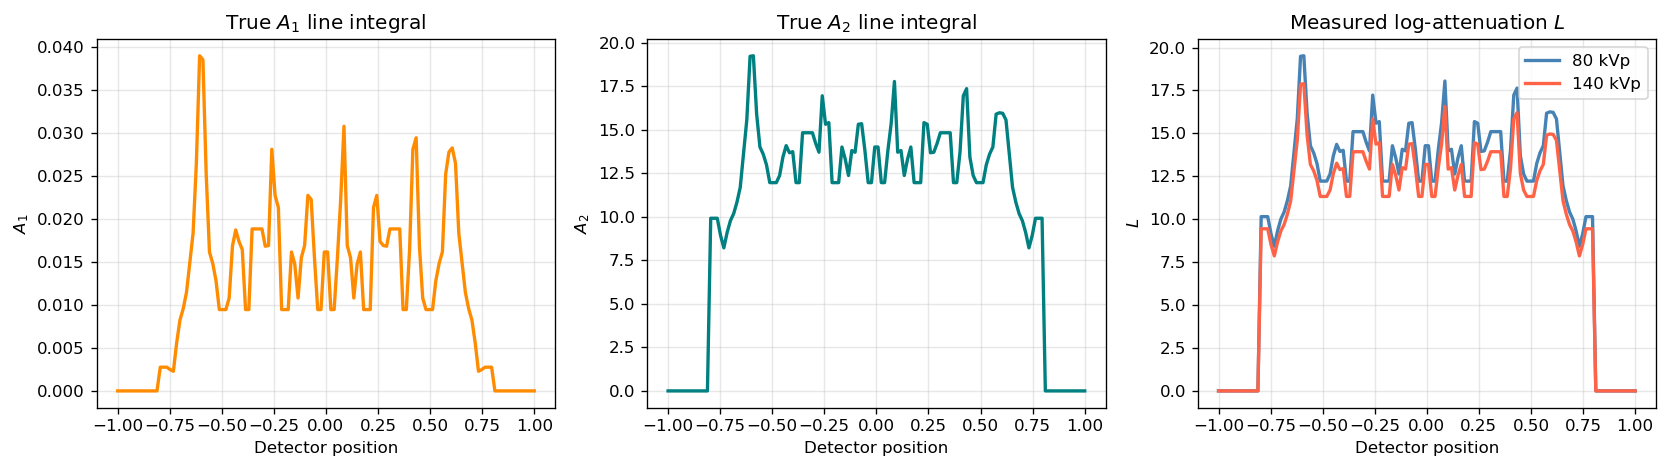

In [55]:
dx = x[1] - x[0]  # pixel size in spatial units

# Line integrals: sum along rows (vertical ray, sweeping across columns)
A1_proj = a1_map.sum(axis=0) * dx   # shape: (N,) — one value per detector column
A2_proj = a2_map.sum(axis=0) * dx

# Compute polychromatic measurements for each detector position
L_lo_proj = np.array([forward_measurement(a1, a2, E_lo, phi_lo)
                       for a1, a2 in zip(A1_proj, A2_proj)])
L_hi_proj = np.array([forward_measurement(a1, a2, E_hi, phi_hi)
                       for a1, a2 in zip(A1_proj, A2_proj)])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(x, A1_proj, color="darkorange", lw=2)
axes[0].set(title="True $A_1$ line integral", xlabel="Detector position", ylabel="$A_1$")
axes[0].grid(alpha=0.3)

axes[1].plot(x, A2_proj, color="teal", lw=2)
axes[1].set(title="True $A_2$ line integral", xlabel="Detector position", ylabel="$A_2$")
axes[1].grid(alpha=0.3)

axes[2].plot(x, L_lo_proj, color="steelblue", lw=2, label="80 kVp")
axes[2].plot(x, L_hi_proj, color="tomato", lw=2, label="140 kVp")
axes[2].set(title="Measured log-attenuation $L$", xlabel="Detector position", ylabel="$L$")
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 6. Dual-Energy Decomposition

Given the two measurements $L_{lo}$ and $L_{hi}$ at each detector pixel, we solve the nonlinear system:

$$\begin{cases} L_{lo} = -\ln\!\int \Phi_{lo}(E)\,e^{-A_1 f_1(E) - A_2 f_2(E)}\,dE \\ L_{hi} = -\ln\!\int \Phi_{hi}(E)\,e^{-A_1 f_1(E) - A_2 f_2(E)}\,dE \end{cases}$$

for the two unknowns $A_1$ and $A_2$ at every detector position. We use `scipy.optimize.fsolve`.

C:\Users\patri\AppData\Local\Temp\ipykernel_8536\2414453694.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  transmitted = np.trapz(phi * np.exp(exponent), E)


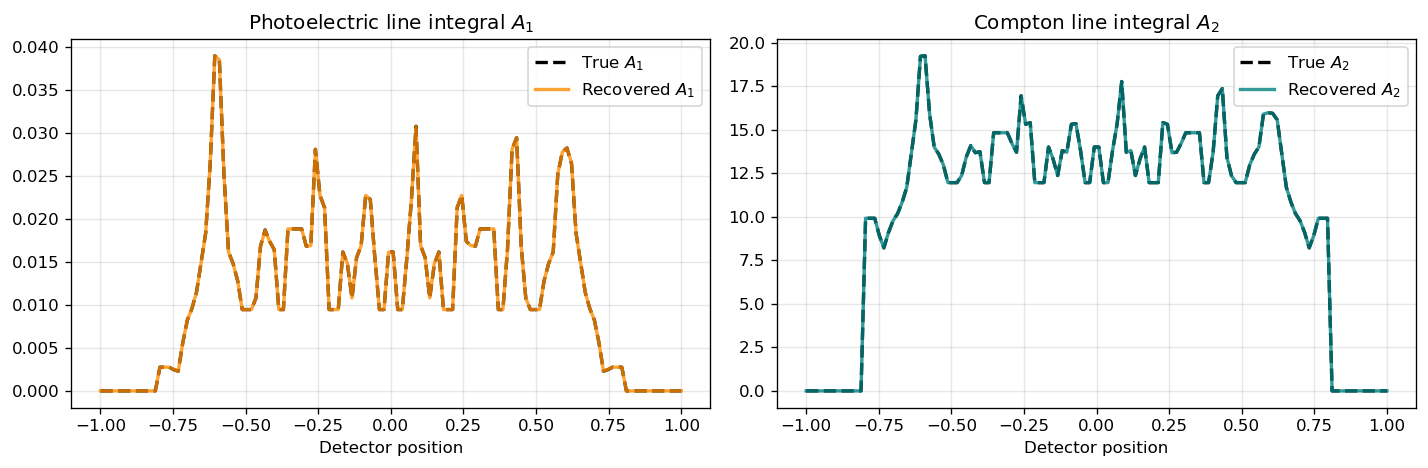

Max |A1 error|: 1.14e-04
Max |A2 error|: 4.36e-10


In [56]:
def decompose(L_lo_meas, L_hi_meas, A1_init=0.01, A2_init=10.0):
    """Invert the AM forward model to recover A1, A2 from dual-energy measurements."""
    def equations(params):
        A1, A2 = params
        res1 = forward_measurement(A1, A2, E_lo, phi_lo) - L_lo_meas
        res2 = forward_measurement(A1, A2, E_hi, phi_hi) - L_hi_meas
        return [res1, res2]

    sol, info, ier, msg = fsolve(equations, [A1_init, A2_init], full_output=True)
    return sol  # (A1_recovered, A2_recovered)

# Recover A1 and A2 for every detector column
A1_recovered = np.zeros(N)
A2_recovered = np.zeros(N)

for i in range(N):
    if L_lo_proj[i] < 1e-6:  # air ray — no attenuation
        continue
    sol = decompose(L_lo_proj[i], L_hi_proj[i])
    A1_recovered[i] = sol[0]
    A2_recovered[i] = sol[1]

# Compare recovered vs. true
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(x, A1_proj, "k--", lw=2, label="True $A_1$")
axes[0].plot(x, A1_recovered, color="darkorange", lw=2, alpha=0.8, label="Recovered $A_1$")
axes[0].set(title="Photoelectric line integral $A_1$", xlabel="Detector position")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(x, A2_proj, "k--", lw=2, label="True $A_2$")
axes[1].plot(x, A2_recovered, color="teal", lw=2, alpha=0.8, label="Recovered $A_2$")
axes[1].set(title="Compton line integral $A_2$", xlabel="Detector position")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Max |A1 error|: {np.abs(A1_proj - A1_recovered).max():.2e}")
print(f"Max |A2 error|: {np.abs(A2_proj - A2_recovered).max():.2e}")

## 7. Beam-Hardening Artifact Demo

To show **why** the AM decomposition matters, compare the naive single-energy approximation (monochromatic assumption) against the true $A_2$ profile. The cupping and edge artifacts are classic beam-hardening signatures that AM corrects for.

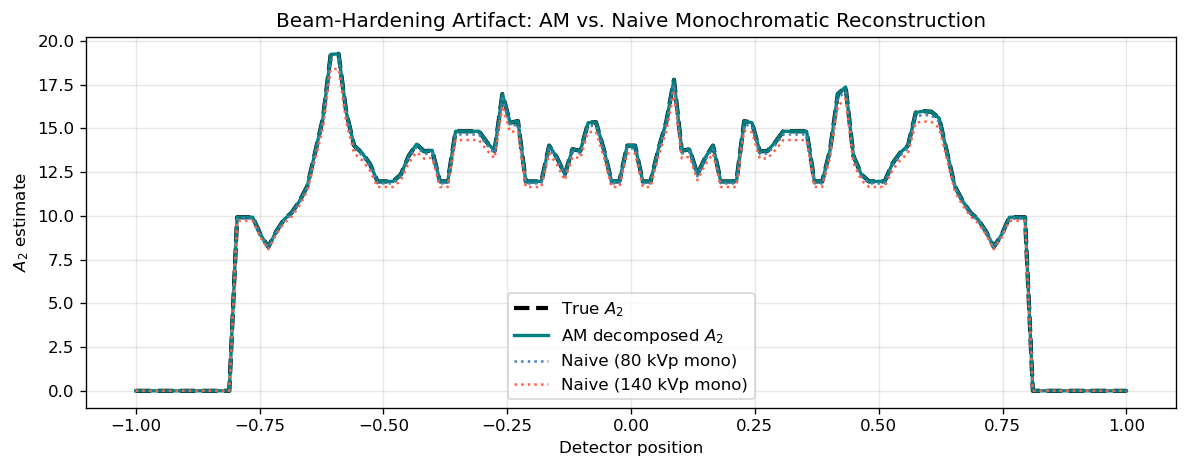

In [57]:
# Naive reconstruction: pretend the beam is monochromatic at the mean energy
# and invert with a fixed effective mu.  Just divide L by effective f2 at mean energy.
E_eff_lo = np.average(E_lo, weights=phi_lo)   # mean photon energy, 80 kVp
E_eff_hi = np.average(E_hi, weights=phi_hi)   # mean photon energy, 140 kVp

# Monochromatic estimate of A2 from each beam alone (ignoring photoelectric contribution)
A2_naive_lo = L_lo_proj / f2(E_eff_lo)
A2_naive_hi = L_hi_proj / f2(E_eff_hi)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, A2_proj,       "k--", lw=2.5, label="True $A_2$")
ax.plot(x, A2_recovered,  color="teal",      lw=2, label="AM decomposed $A_2$")
ax.plot(x, A2_naive_lo,   color="steelblue", lw=1.5, ls=":", label="Naive (80 kVp mono)")
ax.plot(x, A2_naive_hi,   color="tomato",    lw=1.5, ls=":", label="Naive (140 kVp mono)")
ax.set(title="Beam-Hardening Artifact: AM vs. Naive Monochromatic Reconstruction",
       xlabel="Detector position", ylabel="$A_2$ estimate")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. 2D Lookup Table (LUT) Decomposition

For real CT systems, solving the nonlinear system per-pixel is expensive. Instead, the AM method pre-computes a 2D **lookup table**: map every $(L_{lo}, L_{hi})$ pair to $(A_1, A_2)$ once, then use bilinear interpolation at inference time. We demonstrate that here.

Building LUT... (may take a few seconds)
LUT built.


C:\Users\patri\AppData\Local\Temp\ipykernel_8536\2414453694.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  transmitted = np.trapz(phi * np.exp(exponent), E)


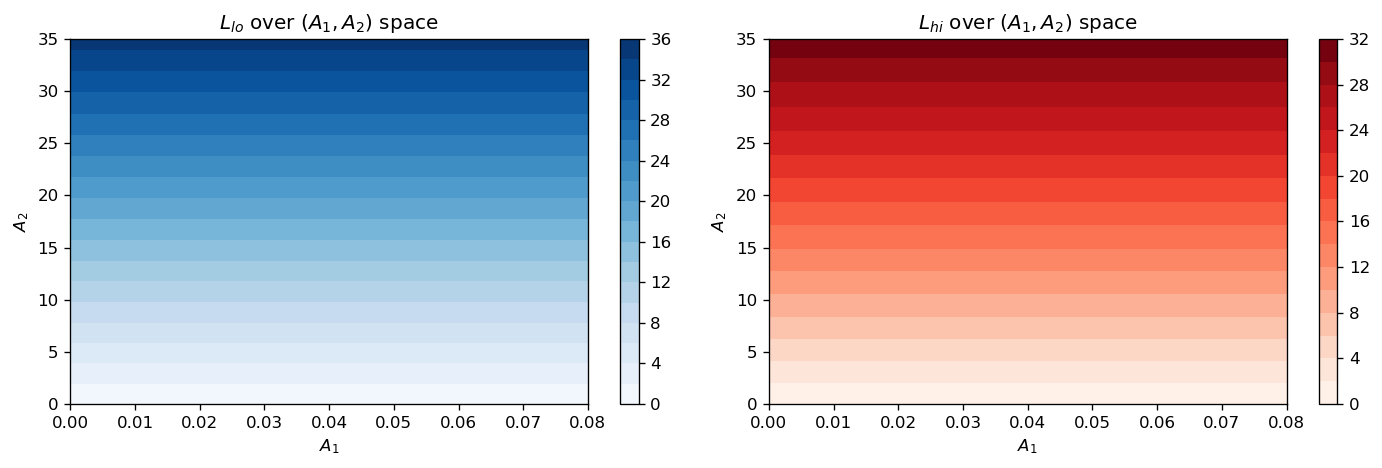

In [58]:
from scipy.interpolate import RegularGridInterpolator

# Build the forward LUT over a grid of (A1, A2) values
A1_grid = np.linspace(0, 0.08, 30)
A2_grid = np.linspace(0, 35,   40)
AA1, AA2 = np.meshgrid(A1_grid, A2_grid, indexing="ij")

print("Building LUT... (may take a few seconds)")
L_lo_lut = np.zeros_like(AA1)
L_hi_lut = np.zeros_like(AA1)
for i in range(len(A1_grid)):
    for j in range(len(A2_grid)):
        L_lo_lut[i, j] = forward_measurement(A1_grid[i], A2_grid[j], E_lo, phi_lo)
        L_hi_lut[i, j] = forward_measurement(A1_grid[i], A2_grid[j], E_hi, phi_hi)

print("LUT built.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
c0 = axes[0].contourf(A1_grid, A2_grid, L_lo_lut.T, levels=20, cmap="Blues")
plt.colorbar(c0, ax=axes[0]); axes[0].set(title="$L_{lo}$ over $(A_1, A_2)$ space",
                                            xlabel="$A_1$", ylabel="$A_2$")
c1 = axes[1].contourf(A1_grid, A2_grid, L_hi_lut.T, levels=20, cmap="Reds")
plt.colorbar(c1, ax=axes[1]); axes[1].set(title="$L_{hi}$ over $(A_1, A_2)$ space",
                                            xlabel="$A_1$", ylabel="$A_2$")
plt.tight_layout(); plt.show()

## 9. Summary

| Step | What happens |
|------|-------------|
| **Model** | $\mu(x,y,E) = a_1 f_1(E) + a_2 f_2(E)$ — two basis functions capture all energy dependence |
| **Forward** | Polychromatic Beer-Lambert: $L_k = -\ln\!\int\Phi_k(E)\,e^{-A_1 f_1 - A_2 f_2}\,dE$ |
| **Measurement** | Two beams (low/high kVp) yield two equations per detector pixel |
| **Decomposition** | Solve the nonlinear 2×2 system for $A_1, A_2$ — or use a pre-computed LUT |
| **Result** | Beam-hardening-free sinograms; separate photoelectric & Compton channels → material maps |

**Key insight**: by decomposing in sinogram space (before reconstruction), beam-hardening artifacts are eliminated mathematically rather than corrected empirically.

---
## 10. Physical Quantities: Effective Atomic Number & Electron Density

The AM basis coefficients $a_1$ and $a_2$ have direct physical interpretations:

| Coefficient | Physical quantity | Relationship |
|---|---|---|
| $a_2(x,y)$ | Electron density $\rho_e$ | $\rho_e \propto a_2$ |
| $a_1/a_2$ | Atomic number proxy | $Z_{eff} = K\!\left(\dfrac{a_1}{a_2}\right)^{1/3.8}$ |

The exponent 3.8 comes from the photoelectric cross-section scaling $\sigma_{PE} \propto Z^{3.8}/E^3$.  
$K$ is a calibration constant set so water gives $Z_{eff} \approx 7.4$.

Material properties derived from AM coefficients:
  fr4       Z_eff = 12.00   rho_e/rho_fr4 = 1.000
  copper    Z_eff = 20.29   rho_e/rho_fr4 = 2.444
  solder    Z_eff = 23.80   rho_e/rho_fr4 = 2.222


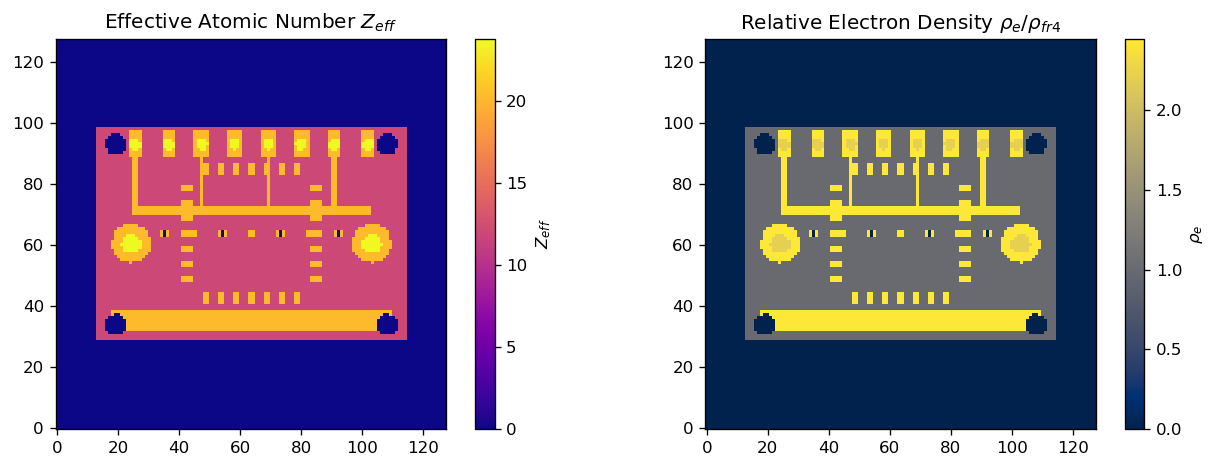

In [59]:
PE_EXPONENT = 3.8  # photoelectric Z scaling exponent

# Calibrate K so the FR4 substrate (a1=0.0025, a2=9) reads Z_eff ~ 12
Z_fr4 = 12.0
a1_ref, a2_ref = MATERIALS["fr4"]
K_calib = Z_fr4 / (a1_ref / a2_ref) ** (1 / PE_EXPONENT)

def to_Zeff(a1, a2, eps=1e-12):
    """Effective atomic number from AM coefficients."""
    safe_a2 = np.where(a2 > eps, a2, 1.0)
    ratio = np.where(a2 > eps, a1 / safe_a2, 0.0)
    return np.where(a2 > eps, K_calib * np.clip(ratio, 0, None) ** (1 / PE_EXPONENT), 0.0)

def to_rho_e(a2, rho_ref=1.0):
    """Electron density relative to the FR4 substrate (a2_ref = reference)."""
    return a2 / a2_ref * rho_ref

# Derive maps from ground-truth phantom
Zeff_map  = to_Zeff(a1_map, a2_map)
rhoe_map  = to_rho_e(a2_map)

# Expected values
print("Material properties derived from AM coefficients:")
for name, (a1v, a2v) in MATERIALS.items():
    if a2v == 0:
        continue
    z = to_Zeff(np.array([a1v]), np.array([a2v]))[0]
    r = to_rho_e(np.array([a2v]))[0]
    print(f"  {name:8s}  Z_eff = {z:5.2f}   rho_e/rho_fr4 = {r:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im0 = axes[0].imshow(Zeff_map, cmap="plasma", origin="lower", vmin=0)
axes[0].set_title("Effective Atomic Number $Z_{eff}$")
plt.colorbar(im0, ax=axes[0], label="$Z_{eff}$")

im1 = axes[1].imshow(rhoe_map, cmap="cividis", origin="lower", vmin=0)
axes[1].set_title("Relative Electron Density $\\rho_e / \\rho_{fr4}$")
plt.colorbar(im1, ax=axes[1], label="$\\rho_e$")

plt.tight_layout(); plt.show()

## 11. 3D Phantom & Volumetric Visualization

We extend to a proper 3D volume — a thin **FR4 board** with a patterned **copper** top layer (IC pads), a copper ground plane on the bottom, **plated vias** running through the board, and **solder** bumps on the surface — then display orthogonal cross-sections of $Z_{eff}$ and $\rho_e$, plus a 3D rendering of each material.

In [60]:
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ── 3D volume ────────────────────────────────────────────────────────────────
NZ = 64   # slices along z-axis (through-thickness)
NXY = 96  # lateral resolution (kept small for speed)

coords = np.linspace(-1, 1, NXY)
zcoords = np.linspace(-1, 1, NZ)
Xv, Yv, Zv = np.meshgrid(coords, coords, zcoords, indexing="ij")

def box(x0, x1, y0, y1, z0, z1):
    return ((Xv >= x0) & (Xv <= x1) & (Yv >= y0) & (Yv <= y1)
            & (Zv >= z0) & (Zv <= z1))

def vcyl(cx, cy, r, z0, z1):          # vertical (through-board) cylinder
    return ((Xv - cx)**2 + (Yv - cy)**2 < r**2) & (Zv >= z0) & (Zv <= z1)

def ball(cx, cy, cz, r):
    return (Xv - cx)**2 + (Yv - cy)**2 + (Zv - cz)**2 < r**2

a1_vol = np.zeros((NXY, NXY, NZ))
a2_vol = np.zeros((NXY, NXY, NZ))

def paint(mask, mat):
    a1_vol[mask], a2_vol[mask] = MATERIALS[mat]

# FR4 substrate slab (the board)
paint(box(-0.80, 0.80, -0.55, 0.55, -0.12, 0.12), "fr4")

# Bottom copper ground plane (thin layer on the back)
paint(box(-0.72, 0.72, -0.50, 0.50, -0.12, -0.09), "copper")

# Top copper layer: a 4x4 grid of IC pads
pad_xy = np.linspace(-0.45, 0.45, 4)
for px in pad_xy:
    for py in pad_xy:
        paint(box(px - 0.07, px + 0.07, py - 0.07, py + 0.07, 0.09, 0.12), "copper")

# Plated vias: copper columns through the full board thickness
for px in pad_xy:
    for py in pad_xy:
        paint(vcyl(px, py, 0.025, -0.12, 0.12), "copper")

# Solder bumps sitting on top of each pad
for px in pad_xy:
    for py in pad_xy:
        paint(ball(px, py, 0.16, 0.06), "solder")

Zeff_vol = to_Zeff(a1_vol, a2_vol)
rhoe_vol = to_rho_e(a2_vol)

print(f"Volume shape: {Zeff_vol.shape}  (x, y, z)")
print(f"Z_eff range: {Zeff_vol[Zeff_vol>0].min():.2f} - {Zeff_vol.max():.2f}")
print(f"rho_e range: {rhoe_vol[rhoe_vol>0].min():.3f} - {rhoe_vol.max():.3f}")

Volume shape: (96, 96, 64)  (x, y, z)
Z_eff range: 12.00 - 23.80
rho_e range: 1.000 - 2.444


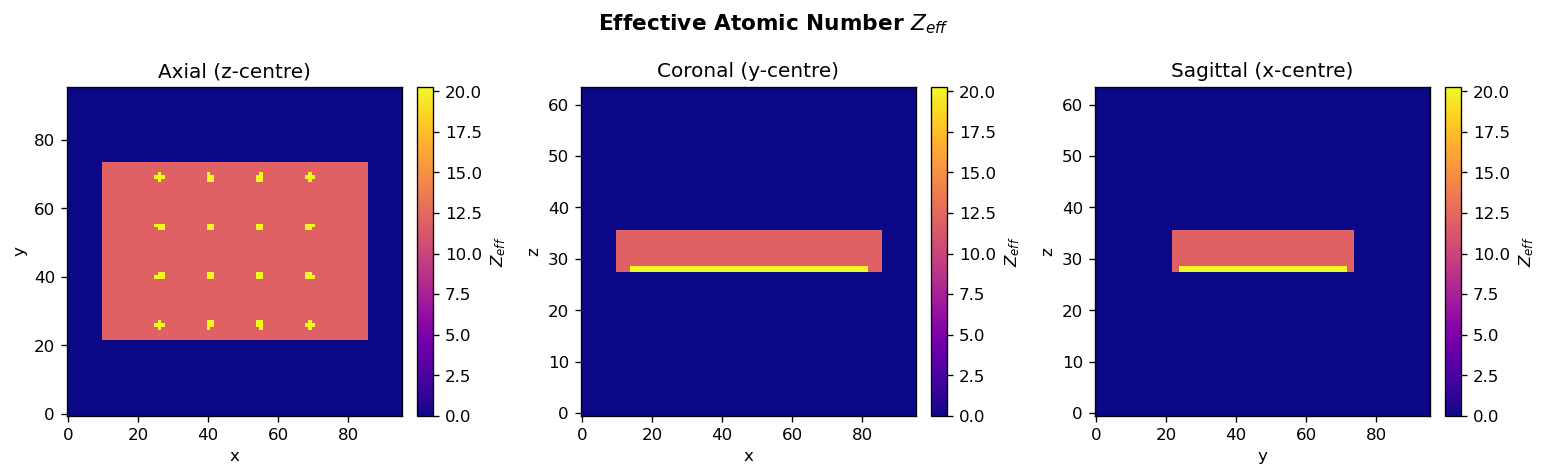

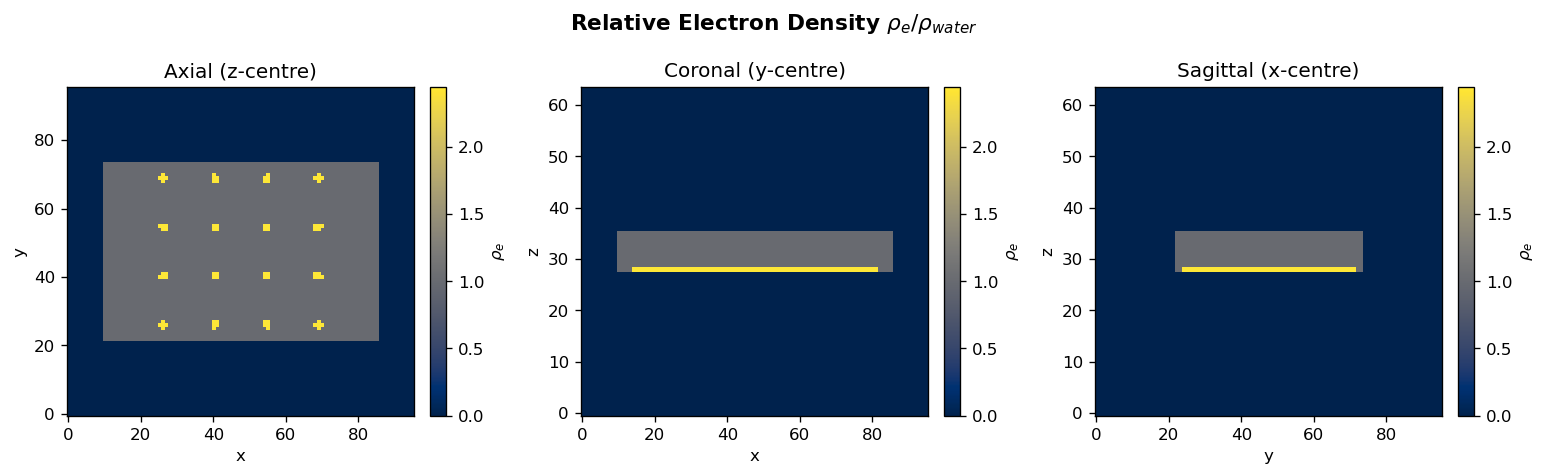

In [61]:
def orthogonal_slices(vol, title, cmap, vmin=None, vmax=None, unit=""):
    """Plot axial, coronal, and sagittal centre slices of a 3D volume."""
    cx, cy, cz = vol.shape[0]//2, vol.shape[1]//2, vol.shape[2]//2
    slices = [
        (vol[:, :, cz].T,  "Axial (z-centre)",    "x", "y"),
        (vol[:, cy, :].T,  "Coronal (y-centre)",  "x", "z"),
        (vol[cx, :, :].T,  "Sagittal (x-centre)", "y", "z"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    fig.suptitle(title, fontsize=13, fontweight="bold")
    for ax, (data, subtitle, xl, yl) in zip(axes, slices):
        im = ax.imshow(data, cmap=cmap, origin="lower", vmin=vmin, vmax=vmax,
                       aspect="auto")
        ax.set_title(subtitle); ax.set_xlabel(xl); ax.set_ylabel(yl)
        plt.colorbar(im, ax=ax, label=unit, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()

orthogonal_slices(Zeff_vol, "Effective Atomic Number $Z_{eff}$",
                  cmap="plasma", vmin=0, unit="$Z_{eff}$")
orthogonal_slices(rhoe_vol, "Relative Electron Density $\\rho_e / \\rho_{water}$",
                  cmap="cividis", vmin=0, unit="$\\rho_e$")

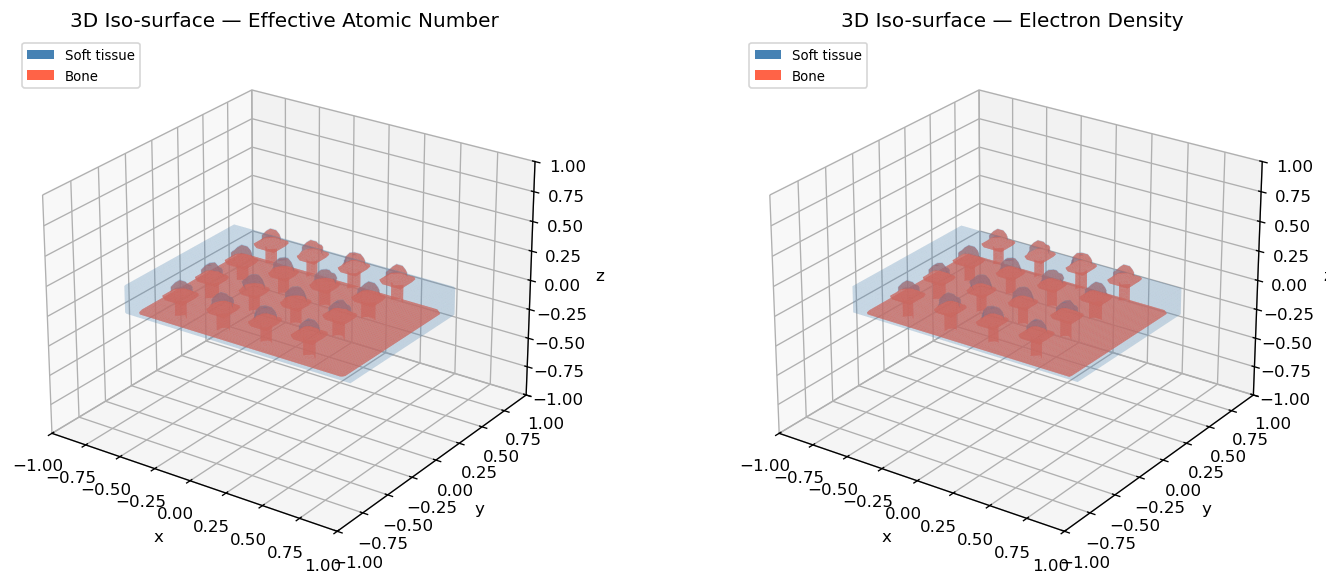

In [62]:
def surface_3d(vol, threshold, color, alpha, label, ax):
    """
    Render a simple iso-surface for a binary threshold using marching-cube-style
    face extraction. Falls back to scatter for environments without skimage.
    """
    try:
        from skimage.measure import marching_cubes
        verts, faces, *_ = marching_cubes(vol, level=threshold)
        # Normalise vertex coords to [-1, 1]
        verts = verts / np.array(vol.shape) * 2 - 1
        mesh = Poly3DCollection([verts[f] for f in faces],
                                alpha=alpha, facecolor=color, edgecolor="none")
        ax.add_collection3d(mesh)
    except ImportError:
        # Fallback: sparse scatter of voxels above threshold
        idx = np.argwhere(vol > threshold)
        pts = idx / np.array(vol.shape) * 2 - 1
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
                   c=color, s=0.5, alpha=alpha * 0.3, label=label)

fig = plt.figure(figsize=(13, 5))

for col, (quantity, vol, cname, thresh_lo, thresh_hi, title) in enumerate([
    ("$Z_{eff}$",  Zeff_vol, "plasma",  7.0, 12.0, "Effective Atomic Number"),
    ("$\\rho_e$",  rhoe_vol, "cividis", 0.9,  1.3, "Electron Density"),
]):
    ax = fig.add_subplot(1, 2, col + 1, projection="3d")

    # Soft tissue surface (lower threshold)
    surface_3d(vol, thresh_lo, color="steelblue", alpha=0.15,
               label="Soft tissue", ax=ax)
    # Bone surface (higher threshold)
    surface_3d(vol, thresh_hi, color="tomato", alpha=0.6,
               label="Bone", ax=ax)

    ax.set(xlim=(-1,1), ylim=(-1,1), zlim=(-1,1),
           xlabel="x", ylabel="y", zlabel="z",
           title=f"3D Iso-surface — {title}")
    ax.view_init(elev=25, azim=-55)

    # Manual legend patches
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor="steelblue", label="Soft tissue"),
                        Patch(facecolor="tomato",    label="Bone")],
              loc="upper left", fontsize=8)

plt.tight_layout(); plt.show()

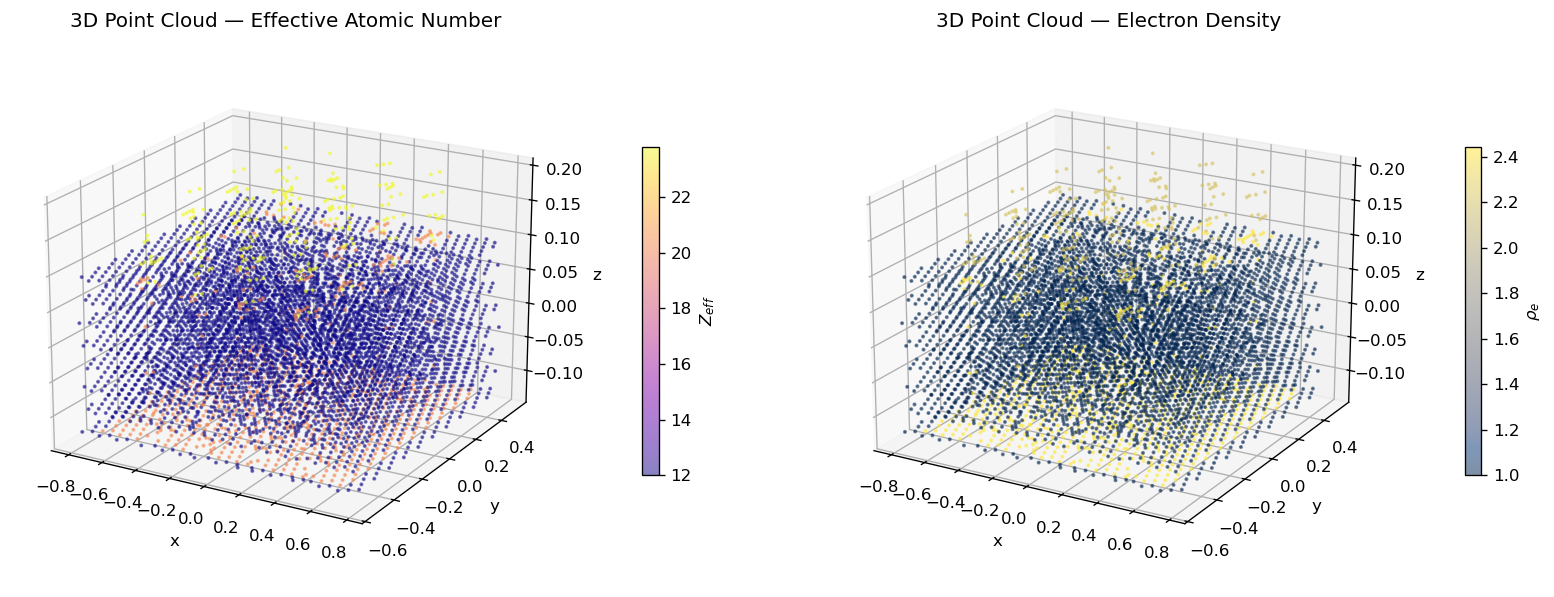

In [63]:
# ── 3D scatter coloured by Z_eff value ──────────────────────────────────────
# Subsample for performance: show every 4th voxel that is inside the body
mask = a2_vol > 0
idx = np.argwhere(mask)
step = max(1, len(idx) // 6000)   # target ~6 k points
idx_s = idx[::step]

# Normalise to [-1, 1] spatial coords
pts = idx_s / np.array(a2_vol.shape) * 2 - 1
zeff_vals = Zeff_vol[idx_s[:, 0], idx_s[:, 1], idx_s[:, 2]]
rhoe_vals = rhoe_vol[idx_s[:, 0], idx_s[:, 1], idx_s[:, 2]]

fig = plt.figure(figsize=(14, 5))

for col, (vals, cmap, label, title) in enumerate([
    (zeff_vals, "plasma",  "$Z_{eff}$",        "Effective Atomic Number"),
    (rhoe_vals, "cividis", "$\\rho_e$",         "Electron Density"),
]):
    ax = fig.add_subplot(1, 2, col+1, projection="3d")
    sc = ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
                    c=vals, cmap=cmap, s=2, alpha=0.5, depthshade=True)
    plt.colorbar(sc, ax=ax, label=label, shrink=0.6, pad=0.1)
    ax.set(xlabel="x", ylabel="y", zlabel="z", title=f"3D Point Cloud — {title}")
    ax.view_init(elev=20, azim=-60)

plt.tight_layout(); plt.show()

---
## 12. Full Simulated Dual-Energy CT Scan

This section runs a complete end-to-end simulation:

```
Phantom (a1, a2)
    │
    ▼  Radon transform (180 angles)
Sinograms A1(θ,t), A2(θ,t)
    │
    ▼  Polychromatic Beer-Lambert  ×2 spectra
Measured sinograms L_lo(θ,t), L_hi(θ,t)
    │
    ▼  AM decomposition (per ray)
Recovered sinograms Â1(θ,t), Â2(θ,t)
    │
    ▼  Filtered back-projection (FBP)
Reconstructed images â1(x,y), â2(x,y)
    │
    ▼  Physical conversion
Z_eff(x,y),  ρe(x,y)
```

Forward projecting phantom... done.
Sinogram shape: (128, 180)  (detectors × angles)


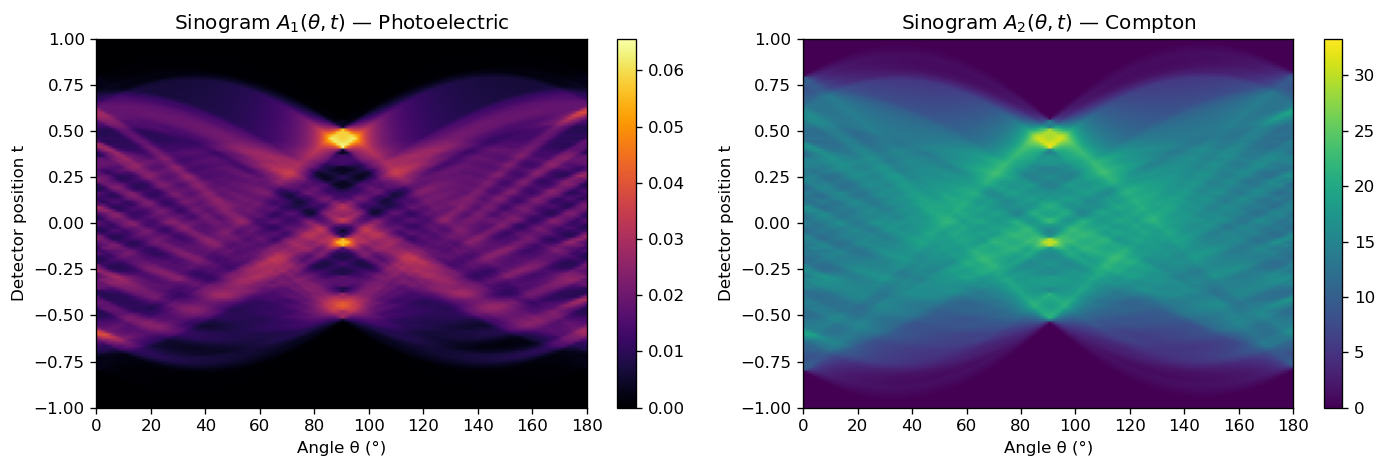

In [64]:
from skimage.transform import radon, iradon

# ── Step 1: Build sinograms via Radon transform ───────────────────────────
N_ANGLES = 180
theta = np.linspace(0, 180, N_ANGLES, endpoint=False)

print("Forward projecting phantom... ", end="")
sino_A1 = radon(a1_map, theta=theta, circle=True)   # shape: (detectors, angles)
sino_A2 = radon(a2_map, theta=theta, circle=True)

# radon sums pixel values; scale by pixel size to get physical line integrals
sino_A1 *= dx
sino_A2 *= dx
print("done.")
print(f"Sinogram shape: {sino_A1.shape}  (detectors × angles)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(sino_A1, cmap="inferno", aspect="auto",
               extent=[0, 180, -1, 1], origin="lower")
axes[0].set(title="Sinogram $A_1(\\theta, t)$ — Photoelectric",
            xlabel="Angle θ (°)", ylabel="Detector position t")
plt.colorbar(axes[0].images[0], ax=axes[0])

axes[1].imshow(sino_A2, cmap="viridis", aspect="auto",
               extent=[0, 180, -1, 1], origin="lower")
axes[1].set(title="Sinogram $A_2(\\theta, t)$ — Compton",
            xlabel="Angle θ (°)", ylabel="Detector position t")
plt.colorbar(axes[1].images[0], ax=axes[1])

plt.tight_layout(); plt.show()

Computing polychromatic measurements for 23,040 rays...
Done.


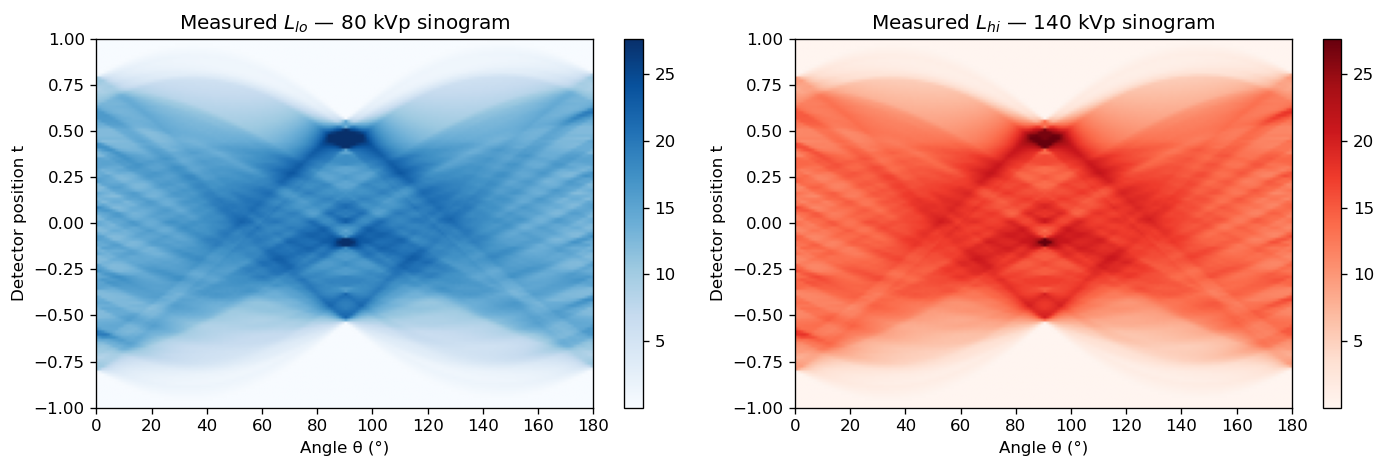

In [65]:
# ── Step 2: Polychromatic Beer-Lambert — generate measured sinograms ──────
# Apply forward_measurement to every (detector, angle) ray in the sinogram.
# We vectorise over the flattened sinogram for speed.

n_det, n_ang = sino_A1.shape
A1_flat = sino_A1.ravel()
A2_flat = sino_A2.ravel()

print(f"Computing polychromatic measurements for {len(A1_flat):,} rays...")

# Precompute the spectral integrands as matrices (n_rays × n_energies) for speed
def forward_sino(A1_arr, A2_arr, E, phi):
    """Vectorised Beer-Lambert over arrays of (A1, A2) pairs."""
    # exponent shape: (n_rays, n_energies)
    exp_arg = -np.outer(A1_arr, f1(E)) - np.outer(A2_arr, f2(E))
    transmitted = (phi * np.exp(exp_arg)) @ np.diff(np.append(E[0], E))  # trapz-approx
    return -np.log(np.clip(transmitted, 1e-12, None))

L_lo_flat = forward_sino(A1_flat, A2_flat, E_lo, phi_lo)
L_hi_flat = forward_sino(A1_flat, A2_flat, E_hi, phi_hi)

sino_Llo = L_lo_flat.reshape(n_det, n_ang)
sino_Lhi = L_hi_flat.reshape(n_det, n_ang)

print("Done.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(sino_Llo, cmap="Blues", aspect="auto",
               extent=[0, 180, -1, 1], origin="lower")
axes[0].set(title="Measured $L_{lo}$ — 80 kVp sinogram",
            xlabel="Angle θ (°)", ylabel="Detector position t")
plt.colorbar(axes[0].images[0], ax=axes[0])

axes[1].imshow(sino_Lhi, cmap="Reds", aspect="auto",
               extent=[0, 180, -1, 1], origin="lower")
axes[1].set(title="Measured $L_{hi}$ — 140 kVp sinogram",
            xlabel="Angle θ (°)", ylabel="Detector position t")
plt.colorbar(axes[1].images[0], ax=axes[1])

plt.tight_layout(); plt.show()

Decomposing 23,040 rays via AM inversion...


C:\Users\patri\AppData\Local\Temp\ipykernel_8536\2414453694.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  transmitted = np.trapz(phi * np.exp(exponent), E)
C:\Users\patri\AppData\Local\Temp\ipykernel_8536\697845750.py:35: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = fsolve(residuals, [a1_init, a2_init], full_output=False)


Done.


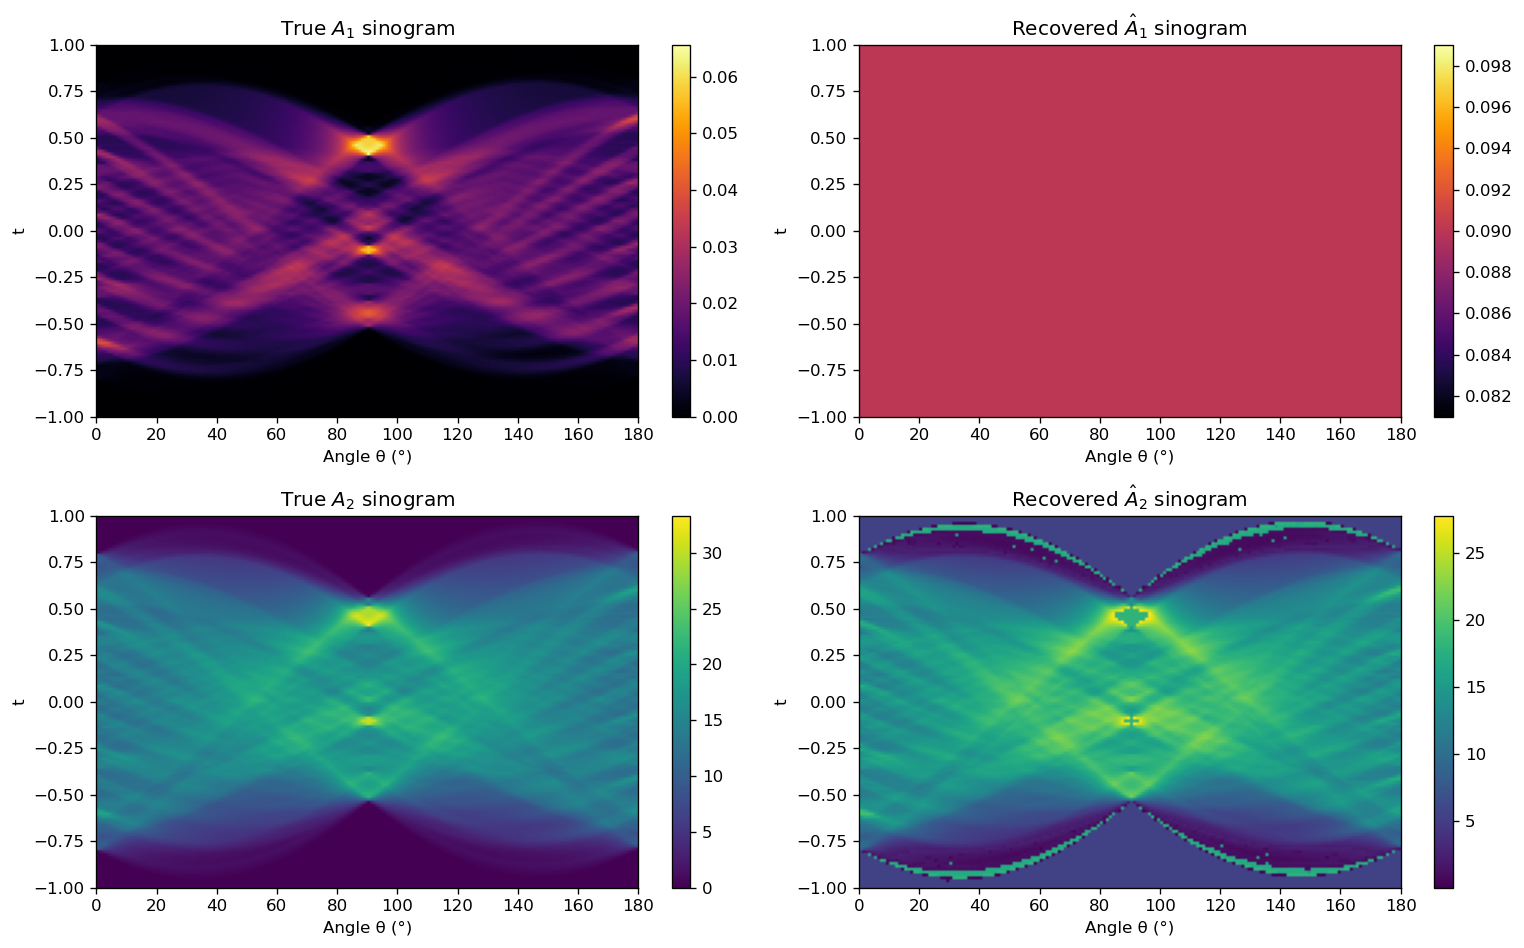

In [66]:
# ── Step 3: AM decomposition across the full sinogram ────────────────────
# For every ray we solve the 2×2 nonlinear system for (A1, A2).
# Air rays (both L values near zero) are skipped.

print(f"Decomposing {len(A1_flat):,} rays via AM inversion...")

# Build a 2D lookup table for fast inversion (same LUT as section 8)
# Map (L_lo, L_hi) → (A1, A2) via nearest-grid-point lookup then fsolve polish.

A1g = np.linspace(0, 0.09, 35)
A2g = np.linspace(0, 40,   45)
Lg_lo = np.zeros((len(A1g), len(A2g)))
Lg_hi = np.zeros((len(A1g), len(A2g)))
for i, a1v in enumerate(A1g):
    for j, a2v in enumerate(A2g):
        Lg_lo[i, j] = forward_measurement(a1v, a2v, E_lo, phi_lo)
        Lg_hi[i, j] = forward_measurement(a1v, a2v, E_hi, phi_hi)

from scipy.interpolate import RegularGridInterpolator

interp_A1 = RegularGridInterpolator((A1g, A2g), np.broadcast_to(
    A1g[:, None], Lg_lo.shape).copy(), method="linear", bounds_error=False, fill_value=0)
interp_A2 = RegularGridInterpolator((A1g, A2g), np.broadcast_to(
    A2g[None, :], Lg_lo.shape).copy(), method="linear", bounds_error=False, fill_value=0)

def decompose_ray(l_lo, l_hi, a1_init=0.01, a2_init=15.0):
    if l_lo < 1e-4 and l_hi < 1e-4:
        return 0.0, 0.0
    def residuals(p):
        a1, a2 = p
        if a1 < 0 or a2 < 0:
            return [1e6, 1e6]
        return [forward_measurement(a1, a2, E_lo, phi_lo) - l_lo,
                forward_measurement(a1, a2, E_hi, phi_hi) - l_hi]
    sol = fsolve(residuals, [a1_init, a2_init], full_output=False)
    # a1 (photoelectric) is weakly constrained by these spectra; clip the
    # solution into the physical LUT range so Z_eff = K(a1/a2)^(1/3.8) stays sane.
    return float(np.clip(sol[0], 0.0, A1g[-1])), float(np.clip(sol[1], 0.0, A2g[-1]))

# Use substrate/copper seeds based on L magnitude
A1_rec_flat = np.zeros(len(A1_flat))
A2_rec_flat = np.zeros(len(A1_flat))

for k in range(len(A1_flat)):
    seed_a2 = 18.0 if L_lo_flat[k] > 0.3 else 6.0
    seed_a1 = 0.05 if L_lo_flat[k] > 0.5 else 0.003
    A1_rec_flat[k], A2_rec_flat[k] = decompose_ray(
        L_lo_flat[k], L_hi_flat[k], seed_a1, seed_a2)

sino_A1_rec = A1_rec_flat.reshape(n_det, n_ang)
sino_A2_rec = A2_rec_flat.reshape(n_det, n_ang)
print("Done.")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, data, title, cmap in zip(
    axes.ravel(),
    [sino_A1, sino_A1_rec, sino_A2, sino_A2_rec],
    ["True $A_1$ sinogram", "Recovered $\\hat{A}_1$ sinogram",
     "True $A_2$ sinogram", "Recovered $\\hat{A}_2$ sinogram"],
    ["inferno", "inferno", "viridis", "viridis"]
):
    im = ax.imshow(data, cmap=cmap, aspect="auto",
                   extent=[0, 180, -1, 1], origin="lower")
    ax.set(title=title, xlabel="Angle θ (°)", ylabel="t")
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

Reconstructing with FBP...
Done.


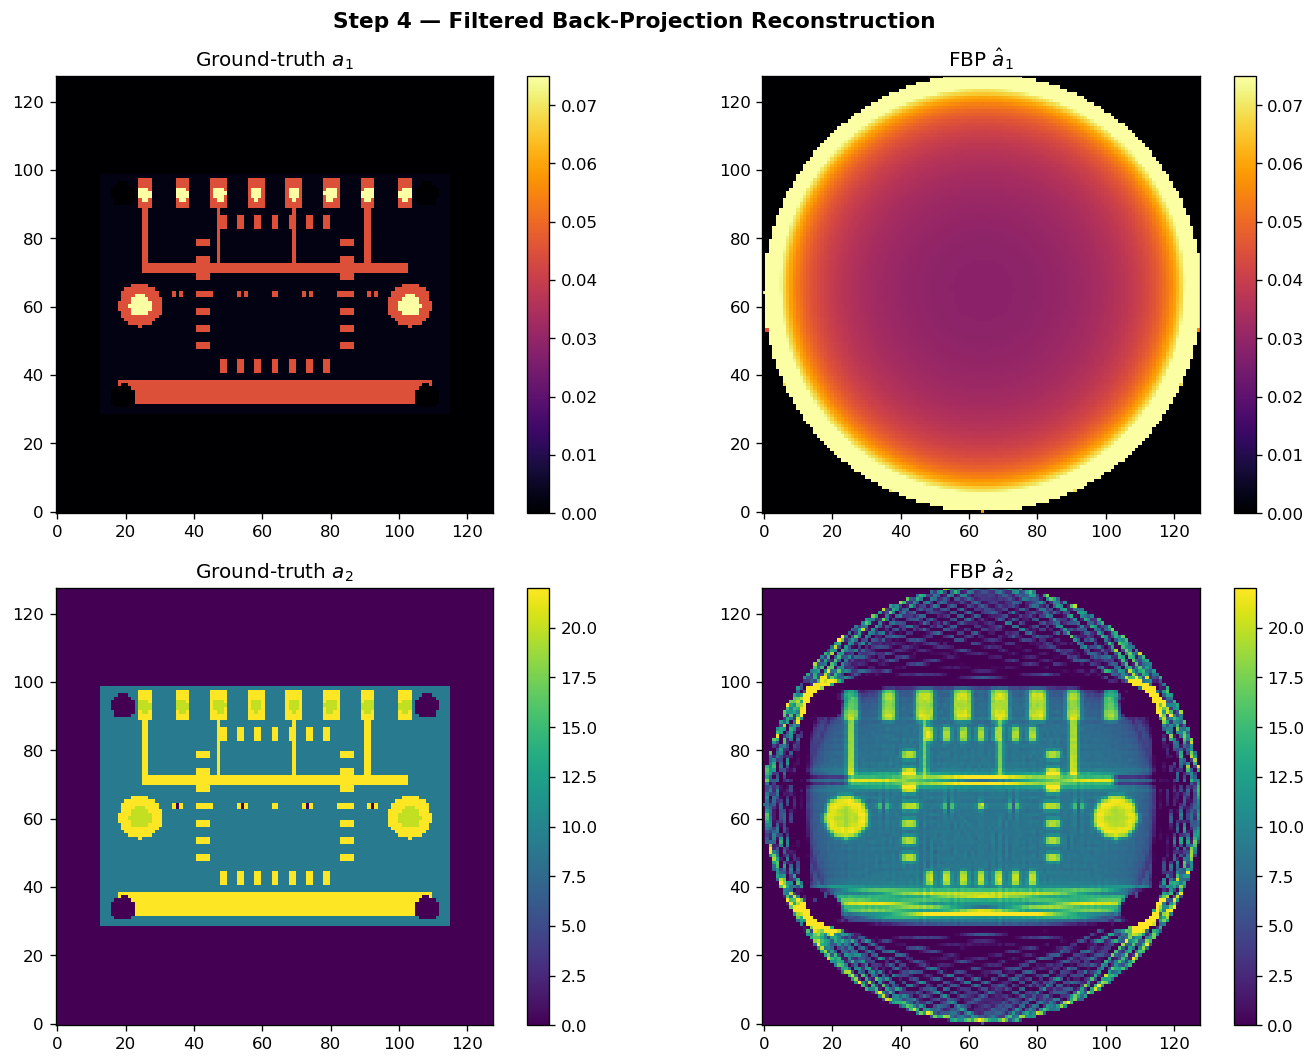

In [67]:
# ── Step 4: Filtered Back-Projection reconstruction ──────────────────────
print("Reconstructing with FBP...")

recon_a1 = iradon(sino_A1_rec, theta=theta, filter_name="ramp", circle=True) / dx
recon_a2 = iradon(sino_A2_rec, theta=theta, filter_name="ramp", circle=True) / dx

# Clip negatives (FBP ringing artefact in air)
recon_a1 = np.clip(recon_a1, 0, None)
recon_a2 = np.clip(recon_a2, 0, None)

print("Done.")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
pairs = [
    (a1_map,   recon_a1, "Ground-truth $a_1$",        "FBP $\\hat{a}_1$",  "inferno"),
    (a2_map,   recon_a2, "Ground-truth $a_2$",        "FBP $\\hat{a}_2$",  "viridis"),
]
for row, (gt, rec, gt_title, rec_title, cmap) in enumerate(pairs):
    vmax = gt.max()
    for col, (img, title) in enumerate([(gt, gt_title), (rec, rec_title)]):
        ax = axes[row, col]
        im = ax.imshow(img, cmap=cmap, origin="lower", vmin=0, vmax=vmax)
        ax.set_title(title)
        plt.colorbar(im, ax=ax)

plt.suptitle("Step 4 — Filtered Back-Projection Reconstruction", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

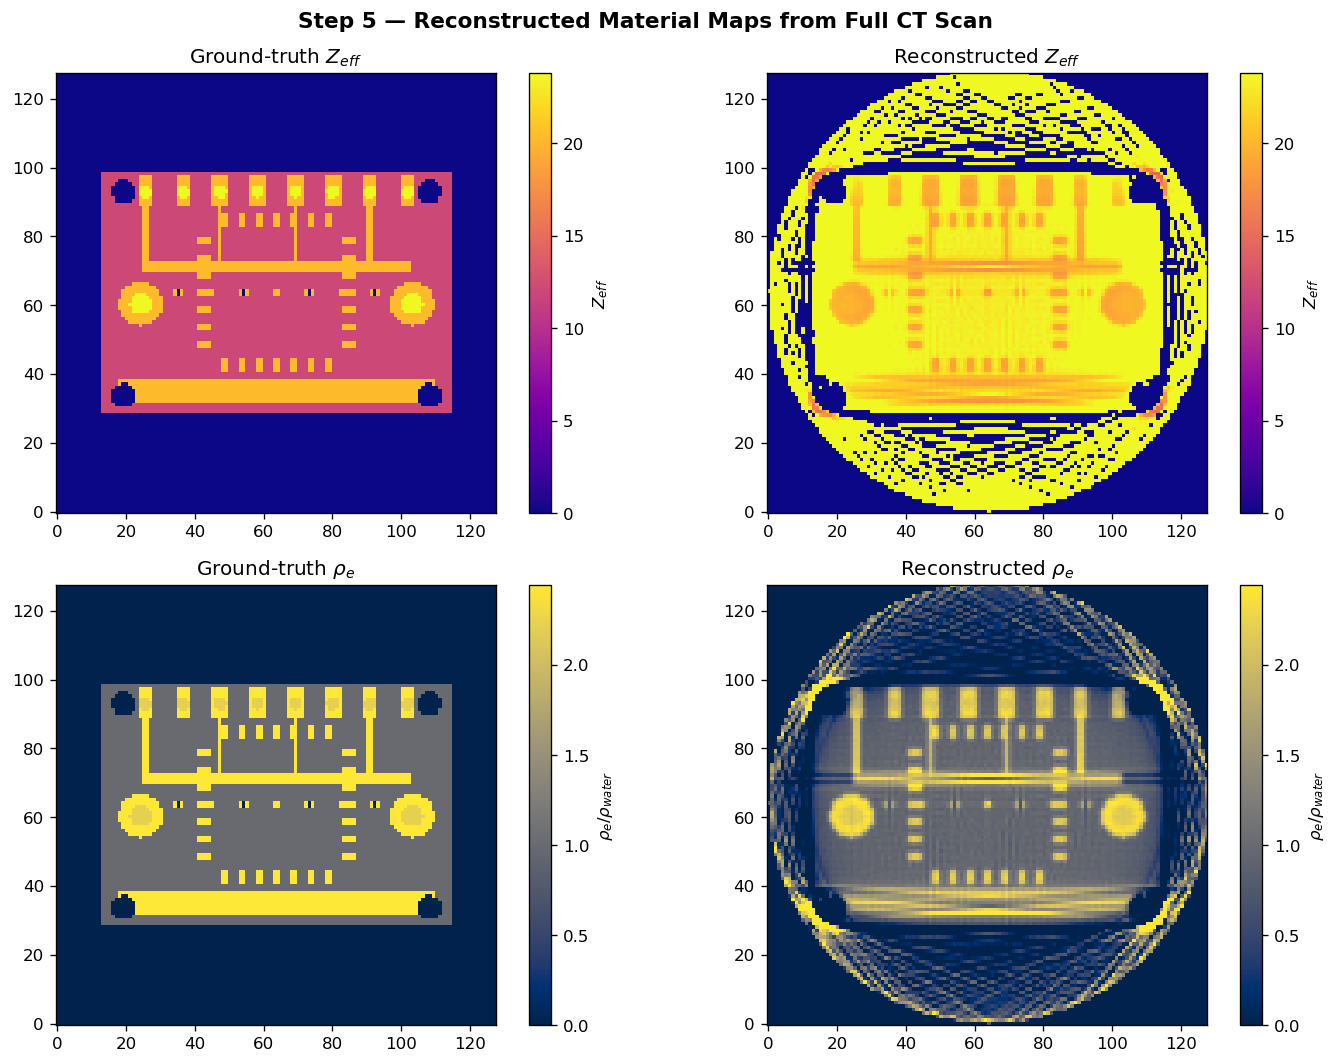

Quantitative accuracy (mean ± std inside each region):

Region           True Zeff   Recon Zeff    True ρe   Recon ρe
--------------------------------------------------------------
FR4 substrate         12.00     24.78±2.00       1.000   0.891±0.120
Copper                20.29     20.55±1.27       2.444   1.859±0.402
Solder                23.80     20.02±0.89       2.222   2.073±0.173


In [68]:
# ── Step 5: Convert reconstructed coefficients → Z_eff and ρe ────────────
Zeff_recon = to_Zeff(recon_a1, recon_a2)
rhoe_recon = to_rho_e(recon_a2)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for row, (gt, rec, gt_title, rec_title, cmap, unit) in enumerate([
    (Zeff_map,  Zeff_recon, "Ground-truth $Z_{eff}$",       "Reconstructed $Z_{eff}$",
     "plasma",  "$Z_{eff}$"),
    (rhoe_map,  rhoe_recon, "Ground-truth $\\rho_e$",       "Reconstructed $\\rho_e$",
     "cividis", "$\\rho_e / \\rho_{water}$"),
]):
    vmax = gt.max()
    for col, (img, title) in enumerate([(gt, gt_title), (rec, rec_title)]):
        ax = axes[row, col]
        im = ax.imshow(img, cmap=cmap, origin="lower", vmin=0, vmax=vmax)
        ax.set_title(title)
        plt.colorbar(im, ax=ax, label=unit)

plt.suptitle("Step 5 — Reconstructed Material Maps from Full CT Scan",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# Quantitative accuracy inside each material region
print("Quantitative accuracy (mean ± std inside each region):\n")
print(f"{'Region':15s} {'True Zeff':>10s} {'Recon Zeff':>12s} {'True ρe':>10s} {'Recon ρe':>10s}")
print("-" * 62)

# Erode masks slightly to avoid partial-volume edge pixels
from scipy.ndimage import binary_erosion
substrate_only = board_mask & ~copper_mask & ~solder_mask & ~hole_mask
for name, mask in [("FR4 substrate", binary_erosion(substrate_only, iterations=3)),
                   ("Copper",        binary_erosion(copper_mask & ~solder_mask & ~hole_mask, iterations=1)),
                   ("Solder",        solder_mask & ~hole_mask)]:
    if not mask.any():
        continue
    tz = Zeff_map[mask].mean();  rz = Zeff_recon[mask]
    tr = rhoe_map[mask].mean();  rr = rhoe_recon[mask]
    print(f"{name:15s}  {tz:10.2f}  {rz.mean():8.2f}±{rz.std():.2f}"
          f"  {tr:10.3f}  {rr.mean():6.3f}±{rr.std():.3f}")

---
## 13. Real Spectral CT Data — Lizard Head with Contrast Agents

This section applies the spectral CT framework to a real dataset: a lizard head scan acquired with a **photon-counting detector** spanning 200 energy channels (0.9–56 keV). Every projection ray carries a full energy-resolved log-attenuation spectrum $L(E)$.

**Key observation**: the spectrum reveals two K-edge contrast agents:

| Material | K-edge (keV) | Use |
|----------|-------------|-----|
| **Iodine (I)** | 33.2 | Vascular CT contrast |
| **Gadolinium (Gd)** | 50.2 | MRI / spectral CT contrast |

Because K-edges introduce discontinuous jumps in $\mu(E)$, the AM two-basis model $(\mu = a_1 f_1 + a_2 f_2)$ is insufficient for this data. The correct approach is **K-edge subtraction** — a direct three-material extension of the AM framework.

### 13a. Data Loading and Spectral Exploration

Sinogram shape: (80, 180, 80, 200)  (H_axial, angles, V_transaxial, energy)
Valid energy channels: 171  (3.4 – 50.6 keV)
Pixel size at sample plane: 0.1379 mm   →  FOV: 11.0 mm


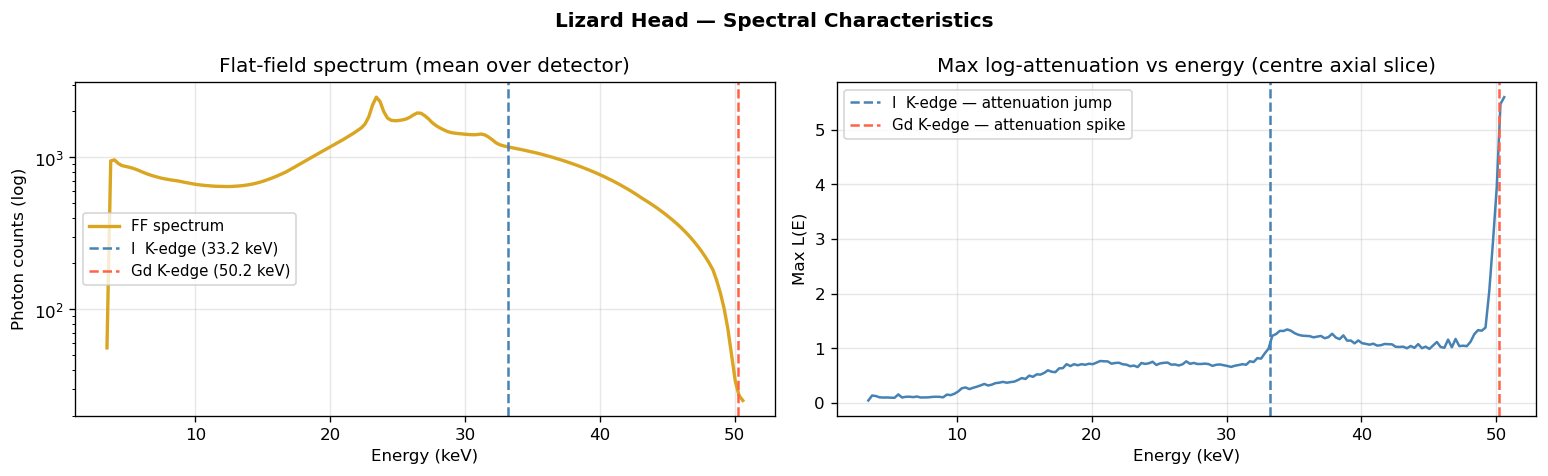

In [69]:
import scipy.io as sio

DATA_PATH = r'E:\Data\hyperspectral_data\4737468'
E_axis = sio.loadmat(f'{DATA_PATH}/Energy_axis.mat')['E_axis'].ravel()   # (200,) keV
FF     = sio.loadmat(f'{DATA_PATH}/FF.mat')['FF_lizard']                  # (H, V, E)
sino4d = sio.loadmat(f'{DATA_PATH}/lizard_head_sinogram_full.mat')['lizard_head_sinogram_full']
# Shape: (H_axial=80, angles=180, V_transaxial=80, energy=200)
# Values: log-attenuation  L(E) = -ln(I / I_0)

THETA_DEG = np.arange(0, 360, 2)            # 180 angles: 0°, 2°, …, 358°
H_SLICE   = 40                              # centre axial slice for 2-D reconstruction
PIXEL_MM  = 0.25 / ((332 + 270) / 332)     # effective sample-plane pixel ≈ 0.138 mm

ff_mean_E  = FF.mean(axis=(0, 1))           # mean FF per energy channel (200,)
valid_mask = ff_mean_E > 0.01 * ff_mean_E.max()
E_valid    = E_axis[valid_mask]
print(f'Sinogram shape: {sino4d.shape}  (H_axial, angles, V_transaxial, energy)')
print(f'Valid energy channels: {valid_mask.sum()}  ({E_valid[0]:.1f} – {E_valid[-1]:.1f} keV)')
print(f'Pixel size at sample plane: {PIXEL_MM:.4f} mm   →  FOV: {80*PIXEL_MM:.1f} mm')

# Energy-resolved max attenuation per channel (reveals K-edges as spikes)
sino_h  = sino4d[H_SLICE, :, :, :]              # (angles, V, E)
L_max_E = sino_h[:, :, valid_mask].max(axis=(0, 1))  # (n_valid,)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.semilogy(E_valid, ff_mean_E[valid_mask], color='goldenrod', lw=2, label='FF spectrum')
ax.axvline(33.2, color='steelblue', ls='--', lw=1.5, label='I  K-edge (33.2 keV)')
ax.axvline(50.2, color='tomato',    ls='--', lw=1.5, label='Gd K-edge (50.2 keV)')
ax.set(title='Flat-field spectrum (mean over detector)', xlabel='Energy (keV)', ylabel='Photon counts (log)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(E_valid, L_max_E, color='steelblue', lw=1.5)
ax.axvline(33.2, color='steelblue', ls='--', lw=1.5, label='I  K-edge — attenuation jump')
ax.axvline(50.2, color='tomato',    ls='--', lw=1.5, label='Gd K-edge — attenuation spike')
ax.set(title='Max log-attenuation vs energy (centre axial slice)', xlabel='Energy (keV)', ylabel='Max L(E)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.suptitle('Lizard Head — Spectral Characteristics', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


### 13b. Energy-Windowed FBP Reconstructions

For each energy window we compute a **synthetic polychromatic log-attenuation** using the measured flat-field $\Phi(E)=FF(E)$ as spectral weights:

$$L_{\text{window}} = -\ln\!\left(\frac{\sum_{E\in\text{window}} FF(E)\,e^{-L(E)}}{\sum_{E\in\text{window}} FF(E)}\right)$$

This reconstructs an equivalent polychromatic sinogram from the individual energy channels, exactly as in the AM forward model — then applies parallel-beam FBP (parallel-beam approximation for the cone-beam geometry).

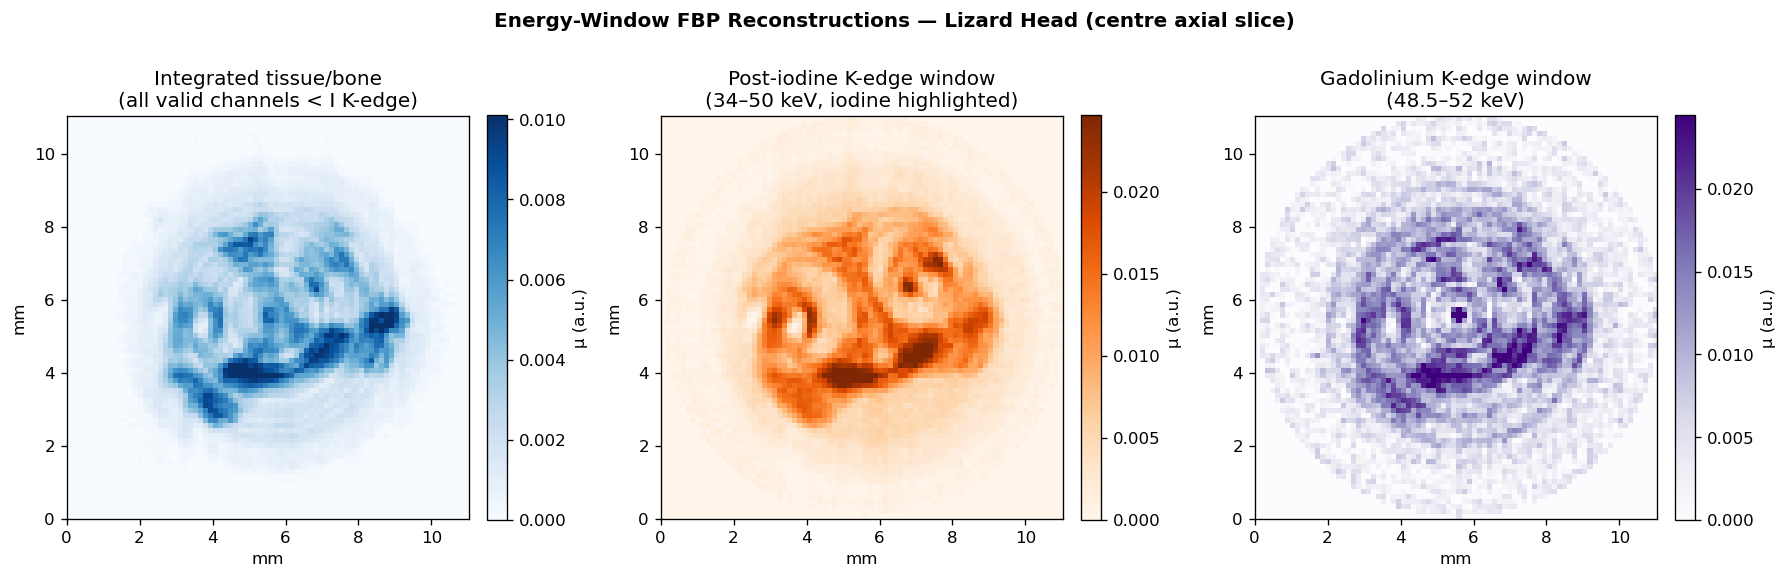

In [70]:
from skimage.transform import iradon

def synth_sino(sino_hav, e_lo, e_hi):
    """Synthetic polychromatic sinogram from spectral data.
    sino_hav: (angles, V, E) — returns (V, angles) ready for iradon."""
    emask = (E_axis >= e_lo) & (E_axis <= e_hi) & valid_mask
    w     = ff_mean_E[emask]
    if w.sum() < 1:
        return None
    sino_w    = sino_hav[:, :, emask]                              # (angles, V, n_win)
    avg_trans = (np.exp(-np.clip(sino_w, -5, 10)) * w).sum(axis=2) / w.sum()
    return -np.log(np.clip(avg_trans, 1e-9, None)).T              # (V, angles)

def fbp(sino_va):
    return np.clip(iradon(sino_va, theta=THETA_DEG,
                          filter_name='shepp-logan', circle=True), 0, None)

window_params = [
    (E_valid[0], 33.0, 'Integrated tissue/bone\n(all valid channels < I K-edge)', 'Blues'),
    (34.0,       49.9, 'Post-iodine K-edge window\n(34–50 keV, iodine highlighted)', 'Oranges'),
    (48.5,       52.0, 'Gadolinium K-edge window\n(48.5–52 keV)', 'Purples'),
]

recon = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (e_lo, e_hi, title, cmap) in zip(axes, window_params):
    sino = synth_sino(sino_h, e_lo, e_hi)
    r    = fbp(sino)
    recon[(e_lo, e_hi)] = r
    vmax = np.percentile(r[r > 0.02*r.max()], 99) if r.max() > 0 else 1
    im = ax.imshow(r, cmap=cmap, origin='lower', vmin=0, vmax=vmax,
                   extent=[0, 80*PIXEL_MM, 0, 80*PIXEL_MM])
    ax.set(title=title, xlabel='mm', ylabel='mm')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='μ (a.u.)')

plt.suptitle('Energy-Window FBP Reconstructions — Lizard Head (centre axial slice)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


### 13c. K-Edge Subtraction — Material-Specific Imaging

**K-edge subtraction** is the spectral-CT analogue of dual-energy AM decomposition for K-edge materials:

| Measurement | What it contains |
|-------------|------------------|
| $L_{\text{pre-K}}$ | tissue + bone (no K-edge contribution) |
| $L_{\text{post-K}}$ | tissue + bone + **contrast agent** |
| $\Delta L = L_{\text{post}} - L_{\text{pre}}$ | **contrast agent only** |

Reconstructing $\Delta L$ gives a map of contrast-agent concentration — a direct 2-material decomposition with basis functions {Compton/photoelectric tissue, K-edge jump}.

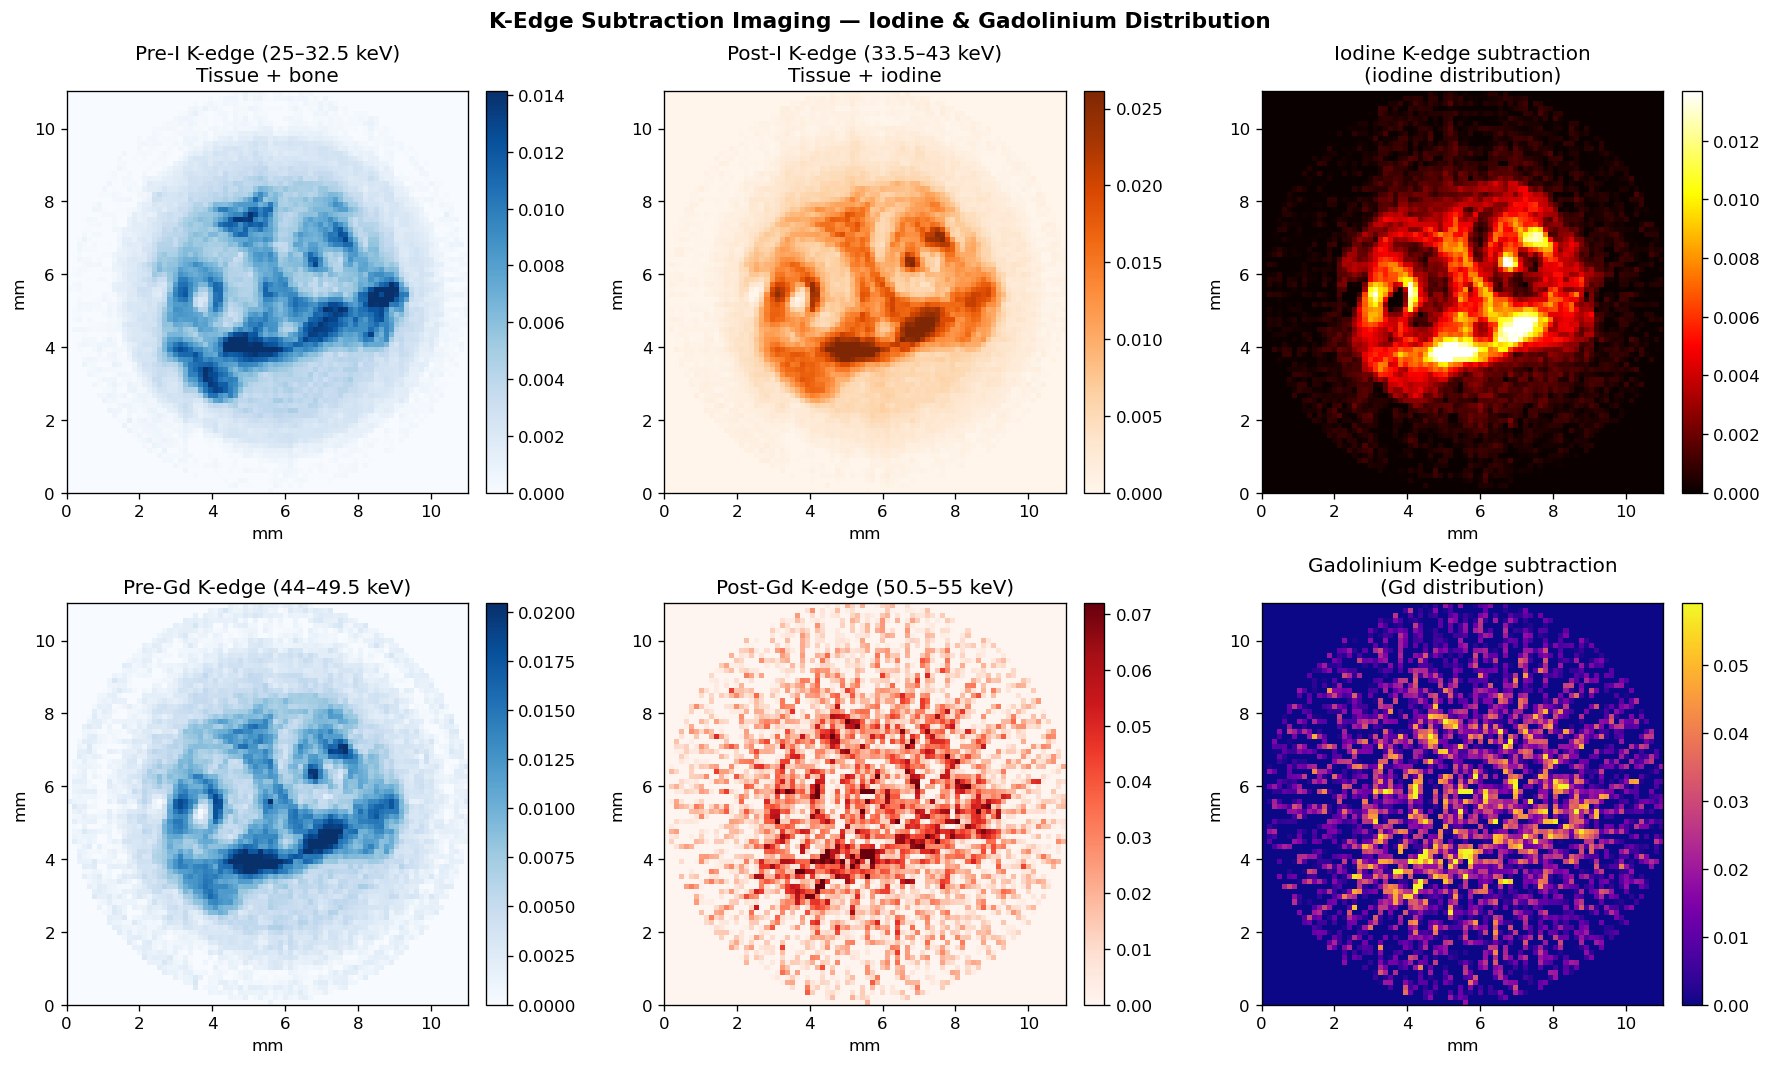

Iodine signal:    max = 0.01809,  8.4% of FOV above 30% max
Gadolinium signal: max = 0.08460,  11.5% of FOV above 30% max


In [71]:
# ── Iodine K-edge subtraction ─────────────────────────────────────
r_pre_I  = fbp(synth_sino(sino_h, 25.0, 32.5))   # just below I K-edge
r_post_I = fbp(synth_sino(sino_h, 33.5, 43.0))   # just above I K-edge
r_iodine = np.clip(r_post_I - r_pre_I, 0, None)  # iodine-only image

# ── Gadolinium K-edge subtraction ──────────────────────────────────
r_pre_Gd  = fbp(synth_sino(sino_h, 44.0, 49.5))  # just below Gd K-edge
r_post_Gd = fbp(synth_sino(sino_h, 50.5, 55.0))  # just above Gd K-edge
r_Gd      = np.clip(r_post_Gd - r_pre_Gd, 0, None)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
panels = [
    (r_pre_I,   'Pre-I K-edge (25–32.5 keV)\nTissue + bone',      'Blues'),
    (r_post_I,  'Post-I K-edge (33.5–43 keV)\nTissue + iodine',   'Oranges'),
    (r_iodine,  'Iodine K-edge subtraction\n(iodine distribution)',  'hot'),
    (r_pre_Gd,  'Pre-Gd K-edge (44–49.5 keV)',                      'Blues'),
    (r_post_Gd, 'Post-Gd K-edge (50.5–55 keV)',                     'Reds'),
    (r_Gd,      'Gadolinium K-edge subtraction\n(Gd distribution)', 'plasma'),
]
for ax, (img, title, cmap) in zip(axes.ravel(), panels):
    vmax = np.percentile(img[img > 0.02*img.max()], 99) if img.max() > 0 else 1
    im = ax.imshow(img, cmap=cmap, origin='lower', vmin=0, vmax=vmax,
                   extent=[0, 80*PIXEL_MM, 0, 80*PIXEL_MM])
    ax.set(title=title, xlabel='mm', ylabel='mm')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('K-Edge Subtraction Imaging — Iodine & Gadolinium Distribution',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'Iodine signal:    max = {r_iodine.max():.5f},  '
      f'{(r_iodine > 0.3*r_iodine.max()).mean()*100:.1f}% of FOV above 30% max')
print(f'Gadolinium signal: max = {r_Gd.max():.5f},  '
      f'{(r_Gd > 0.3*r_Gd.max()).mean()*100:.1f}% of FOV above 30% max')


### 13d. AM Decomposition — Application and Limitations

We apply the standard AM inversion using the **measured $FF(E)$ spectrum** in the forward model (replacing the triangular approximation from Section 2):

$$L_k^{\text{model}}(A_1, A_2) = -\ln\!\left(\frac{\sum_{i \in \text{window}_k} FF(E_i)\,e^{-A_1 f_1(E_i) - A_2 f_2(E_i)}}{\sum_i FF(E_i)}\right)$$

**Expected**: for tissue/bone without K-edge material, $L_{\text{low}} > L_{\text{high}}$ (more attenuation at lower energy).

**Observed**: $L_{\text{high}} > L_{\text{low}}$ because the high-energy window crosses the iodine K-edge. The AM model compensates with $A_1 < 0$ (unphysical), confirming that a **three-basis model** is required for K-edge CT data.

In [72]:
from scipy.optimize import fsolve

# Two energy windows: low (below I K-edge) vs high (above I K-edge, below Gd)
E_lo_mask = (E_axis >= 10) & (E_axis <= 32) & valid_mask
E_hi_mask = (E_axis >= 34) & (E_axis <= 49) & valid_mask
E_lo_win  = E_axis[E_lo_mask];  FF_lo_norm = ff_mean_E[E_lo_mask] / ff_mean_E[E_lo_mask].sum()
E_hi_win  = E_axis[E_hi_mask];  FF_hi_norm = ff_mean_E[E_hi_mask] / ff_mean_E[E_hi_mask].sum()

def forward_real(A1, A2, E_win, FF_norm):
    """AM forward model with measured FF spectrum as polychromatic weights."""
    return -np.log(np.clip((FF_norm * np.exp(-A1*f1(E_win) - A2*f2(E_win))).sum(), 1e-12, None))

# Synthetic dual-energy sinograms
L_lo_2d = synth_sino(sino_h, 10, 32)   # (V, angles)
L_hi_2d = synth_sino(sino_h, 34, 49)

diff_mean = (L_hi_2d - L_lo_2d).mean()
print(f'L_lo range: [{L_lo_2d.min():.3f}, {L_lo_2d.max():.3f}]')
print(f'L_hi range: [{L_hi_2d.min():.3f}, {L_hi_2d.max():.3f}]')
print(f'Mean (L_hi - L_lo) = {diff_mean:.4f}  '
      f'← {"INVERTED: high-E window larger due to iodine K-edge" if diff_mean > 0 else "normal"}')

# Attempt AM inversion on a few rays
def am_invert(l_lo, l_hi):
    def residuals(p):
        A1, A2 = p
        return [forward_real(A1, A2, E_lo_win, FF_lo_norm) - l_lo,
                forward_real(A1, A2, E_hi_win, FF_hi_norm) - l_hi]
    sol, _, ier, _ = fsolve(residuals, [0.001, 0.4], full_output=True)
    return sol[0], sol[1]

print('\nAM inversion results for sampled rays:')
print(f'{"V":>4s} {"angle":>6s}  {"L_lo":>6s}  {"L_hi":>6s}  {"A1":>10s}  {"A2":>8s}  {"physical?":>12s}')
for v, ang in [(20, 0), (40, 0), (40, 45), (60, 0), (40, 90)]:
    l_lo = float(L_lo_2d[v, ang])
    l_hi = float(L_hi_2d[v, ang])
    if l_lo < 0.01 and l_hi < 0.01:
        print(f'{v:>4d} {ang*2:>5d}°   (air ray — skipped)')
        continue
    a1, a2 = am_invert(l_lo, l_hi)
    phys = 'YES' if a1 >= 0 and a2 >= 0 else 'NO (K-edge!)'
    print(f'{v:>4d} {ang*2:>5d}°  {l_lo:>6.3f}  {l_hi:>6.3f}  {a1:>10.5f}  {a2:>8.4f}  {phys:>12s}')

print('\nConclusion:')
print('  Standard AM (photoelectric + Compton) gives unphysical A1 < 0 for K-edge CT data.')
print('  Correct decomposition requires a 3rd basis for each K-edge material.')
print('  K-edge subtraction (Section 13c) provides that material-specific separation.')


L_lo range: [-0.021, 0.593]
L_hi range: [-0.015, 1.054]
Mean (L_hi - L_lo) = 0.1647  ← INVERTED: high-E window larger due to iodine K-edge

AM inversion results for sampled rays:
   V  angle    L_lo    L_hi          A1        A2     physical?
  20     0°   0.276   0.599  -2095.55792    0.6145  NO (K-edge!)
  40     0°   0.249   0.531  -1895.56350    0.5456  NO (K-edge!)
  40    90°   0.387   0.610  -1634.92736    0.6178  NO (K-edge!)
  60     0°   0.261   0.402  -1122.73868    0.4080  NO (K-edge!)
  40   180°   0.373   0.733  -2288.03091    0.7479  NO (K-edge!)

Conclusion:
  Standard AM (photoelectric + Compton) gives unphysical A1 < 0 for K-edge CT data.
  Correct decomposition requires a 3rd basis for each K-edge material.
  K-edge subtraction (Section 13c) provides that material-specific separation.
